# Buying the near token after a Binance burst while the book has not moved: which stale window, definition, discount to fair value and limit earn on weeks they were not chosen on, and what does a later order cost?

## S0 · Summary

**The thesis.** After a 3-sigma Binance burst the move persists, and a Polymarket 15-minute Up/Down book that has not re-priced it leaves the near token (the
side the burst points to) under its driftless fair value. Test E of the buy-near tests (um-021) reads that mechanism directly: rule A plus the near ask equal
to its ask 3 seconds earlier. On the 38 seated days it was the only rule of seven whose interval cleared zero. This notebook explores E as a strategy.

**Second pass (2026-10-11), the owner: "make sure we tune E well."** The first pass searched seven dimensions on one train, validate and test split, and its
best cell sat on a spike and lost the test week. This pass tunes only what the thesis gives a mechanism (the stale window, the definition of a book that has
not moved, the discount to fair value, the fill limit), fixes the rest at E's levels, chooses every week on the weeks before it, and takes the centre of a plateau
along the window instead of the best single cell.

**What it holds.**

| Part | Question |
|---|---|
| S3.1 | E as it stands on 38 days: the summary, the equity, each entry, each coin, the prices paid, the winners and losers, the biggest win and loss on the book |
| S3.2 | The surface: every cell of the small grid (window x definition x discount to fair value x limit) on every seated day, described, not chosen |
| S3.3 | The walk-forward: each week from the second chosen on the weeks before it by the plateau rule, E tuned against E as built and rule A on the same days |
| S3.4 | Is the choice stable from week to week, and does the week it is applied to agree |
| S3.5 | The final cell (the plateau centre on every day), its honest read, the latency ladder, the fee sweep and its live spec |
| S4 | Out of sample and luck, latency from 150 ms to 5,250 ms (per entry, in dollars, and which entries a later order loses), fees and slippage, slices, steadiness, exits, on the final cell and on E |
| S5 | The daily record, the drawdown, concentration and the pre-registered stop |
| S6 | Capacity under both fill limits, the gates, the size or "information only" |
| S7 | The verdict and the next bet |

**Three definitions of a book that has not moved** (n seconds): (a) the near ask now equals the near ask n seconds ago (E as built: endpoints only, so an ask
that moved and came back counts); (b) the near ask is unchanged at every second of the last n; (c) the near ask and its size at the touch are unchanged at every
second (nobody traded or re-quoted the touch). The Down token's ask is 1 minus the Up bid, so for a Down buy the Up bid and its size are read.

**Two fill limits:** the ask seen at the decision second (E as built: the order takes what rests at or under it 250 ms later and stops) and our edge price,
fair value less the discount (every level under it still carries the edge the rule asks for). In this pass the limit is a tuned dimension.

**Engine caveats (the timing audit of 2026-10-11).** The gate reads the book at the Binance print, before a live order could know of it, and a frozen feed
passes "the book has not moved" by construction; neither is corrected in the engine this run used. Both are counted where they bite (S3.3, S4.2, S7).

In [1]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_The summary card is drawn here when the run finishes._"), display_id=True)

**Buying the near token after a Binance burst while the book has not moved: which stale window, definition, discount to fair value and limit earn on weeks they were not chosen on, and what does a later order cost?** · **NO SIZE**

**Research question** Which stale window, definition, discount and limit of the stale-book rule earn on weeks they were not chosen on, without the best 5%?

NO SIZE, class B. E tuned out of sample: 161 entries net +381 USD (+2.36 each, 95% -0.65 to +5.75); without the best 5% -0.39.

**Implementation**

| | |
|:--|:--|
| Trade | Buy the near token after a burst, book not moved |
| Venue | Polymarket 15m crypto Up/Down; Binance is input |
| Rule | c6\|th0.05\|edge |
| Size | USD 20 a trade, USD 1,000 book, 1x |
| Costs | taker fee 0.07 x p(1-p); +250 ms |
| Window | 09-02 to 10-09, 912h, 1 regime |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| test | Net per entry | +2.36 USD | 95% -0.65 to +5.75 | PASS |
| test | Without best 5% | -0.39 USD | above 0 | FAIL |
| test | Win rate | 72.7% | needed 63.2% | INFO |
| test | Deflated Sharpe | 0.00 | at least 0.90 | FAIL |

**Money**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Net per entry | +2.36 USD | above 0 | PASS |
| Before costs, per entry | +2.72 USD |  | INFO |
| Fee, per entry | 0.36 USD |  | INFO |
| E as built, same days | +1.36 USD |  | INFO |

**Is it real**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Tuned beats E | no | yes | FAIL |
| Same window | 1 of 5 | 4 of 5 | FAIL |
| Weeks agree | 3 of 5 | 4 of 5 | FAIL |
| Out-of-sample blocks | not both | both | FAIL |
| Plateau | holds | holds | PASS |
| Random burst p | 0.2577 | below 0.10 | FAIL |

**Delay and cost**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| 1,250 ms, per entry | +0.53 | above 0 | PASS |
| Fee x2, per entry | +2.01 | above 0 | PASS |

**Risk, USD**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Deepest drawdown | -41 | limit -150 | PASS |
| Worst day | -22 |  | INFO |
| Steadiness r2 | 0.91 | low end 0.80 | FAIL |

**Checks**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Windows with a book | 94% | 90% bar | PASS |
| Live replay | agrees | agrees | PASS |
| Cells tried | 162 |  | INFO |
| Checks held | 46 of 46 | all | INFO |

**Size**

| Size | Net, USD | Per entry | Verdict |
|:--|--:|--:|:--|
| 1x info only | +381 | +2.36 | FAIL |

um-023 second pass, 2026-10-11: 162 cells, each week chosen on the weeks before it; the first pass's grid is in git.  
The 38 days were read whole by um-021 (where E was found); only the walk-forward record is out of sample for a choice.  
912h, 46/46 checks; gate at the Binance print; 18 frozen-feed entries of E not masked.


## S1 · Setup

### S1.1 · Parameters

In [2]:
# ---- the study's parameters; the second-pass grid names its own levels here and in tf15_stale.TUNE_LEVELS (asserted equal, registered before any cell is scored) ----
STUDY_ID = "2026-10-11-predmkts-binance-burst-15m-updown-stale-book"
RUN_ID = "um-023"
DESK = "lab/predmkts"
DAYS = ['2026-09-02', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-12', '2026-09-13', '2026-09-14', '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18', '2026-09-19', '2026-09-20', '2026-09-21', '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26', '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30', '2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04', '2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09']
WEEK = 7                                                 # walk-forward weeks by day index; also the tf15_oos fold length
TUNE_LEVELS = dict(kind=("a", "b", "c"), n=(1, 2, 3, 4, 5, 6, 8, 10, 12), theta=(0.03, 0.05, 0.08), limit=("ask", "edge"))   # theta: the discount to fair value, USD a share (3, 5, 8 c)
TUNE_FIXED = dict(z_min=3.0, L=10, t_min=300, band="any")      # E's own levels: |z| 3 over 10 s, at least 300 s left, any ask band
N_REGISTERED = 162                                            # 9 windows x 3 definitions x 3 discounts to fair value (3, 5, 8 c) x 2 limits (the ledger note of 2026-10-11)
E_CELL = dict(kind="a", n=3, theta=0.05, limit="ask")          # test E of um-021 as built
TUNE_N_MIN = 60                                           # a cell is chosen only with at least this many entries on the choosing weeks
STABLE_MIN = 4                                             # G-stable: the chosen window the same in at least this many folds
CLIP_USD, BOOK_USD = 20.0, 1000.0
VENUE_HOLD_MS, OWN_MS = 150, 100                         # the venue's taker hold [1]; our own tick-to-trade, ASSUMED until measured live [U]
LAT_MS = VENUE_HOLD_MS + OWN_MS
EXTRA_S = (1, 2, 3, 5)                                   # whole seconds added to the 250 ms table: 1,250 to 5,250 ms
FEE_MULTS = (0.0, 0.5, 1.0, 1.5, 2.0, 3.0)
SLIPS = (0.0, 0.01, 0.02)                                # the limit raised over the ask seen, USD a share
N_IS, N_OOS = 14, 14                                  # tf15_oos blocks by day index
N_DRAWS, P_GATE = 1000, 0.10
STOP_DAY_USD = 60.0                                      # PRE-REGISTERED [U]: the paper run stops for the day after a day's loss of three clips
DD_LIMIT_USD = 150.0                                     # PRE-REGISTERED [U]: the drawdown limit, 15% of the book
R2_MIN = 0.80                                            # PRE-REGISTERED [U]: the steadiness gate on the daily equity line
DSR_MIN = 0.90

In [3]:
import datetime as dt, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, report as REPORT, summary_card
import tf15_bt as B, tf15_cands as C, tf15_trade_figs as TF, lift_figs as LF, tf15_oos as O, tf15_oos_figs as OF, tf15_stale as ST, tf15_runner as RUNNER
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
LF.setup()
plt.rcParams["figure.dpi"] = 72
assert TUNE_LEVELS == ST.TUNE_LEVELS and TUNE_FIXED == ST.TUNE_FIXED, "the parameters are not the module's grid"
t0 = time.time()
TAB = B.Tab(DAYS, fill_ms=LAT_MS)
ALL_IDX = np.arange(len(DAYS))
CAND = C.BuyNearStale()
CFG_E = ST.tune_cell(**E_CELL)
CFG_A = dict(CFG_E, n=0, name="A")
E_ALL = B.concat(CAND.run(TAB, CFG_E, {}))
A_ALL = B.concat(CAND.run(TAB, CFG_A, {}))
import inspect
_NOFEED = {"feed": False} if "feed" in inspect.signature(C.near_tests).parameters else {}       # this run is on the engine without the feed mask (see S0)
TESTS_U21, MASKS_U21 = C.near_tests(TAB, **_NOFEED)        # um-021's own code: E and A here must be its tests E and A
_same = lambda a_, b_: len(a_["net"]) == len(b_["net"]) and np.array_equal(a_["w"], b_["w"]) and np.array_equal(a_["k"], b_["k"]) and np.allclose(a_["net"], b_["net"])
assert _same(E_ALL, TESTS_U21["E"]) and _same(A_ALL, TESTS_U21["A"]), "the grid's E or A cell is not um-021's test"
S_E, S_A = ST.stats5(E_ALL), ST.stats(A_ALL)
HALF = len(DAYS) // 2
FIGURES = []
WIN = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · the fill {LAT_MS} ms after the decision"
ASSET = list(TF.COINS)
N_AXIS = figstyle.NEUTRAL["axis"]
sgn = lambda v_, d_=2: "n/a" if v_ is None or not np.isfinite(v_) else f"{v_:+,.{d_}f}"
pct = lambda v_, d_=1: "n/a" if v_ is None or not np.isfinite(v_) else f"{v_ * 100:.{d_}f}%"
OLD_E = ST.old_book(TAB, E_ALL)                            # the timing audit's frozen-feed entries (a book row 2 s old or more), still in this engine
FEED_LIVE = C.feed_live(TAB) if hasattr(C, "feed_live") else None      # the feed mask another change adds (every book of the slot silent = a hole); counted, not applied
silent = lambda e_: (int((~FEED_LIVE[e_["w"], e_["k"]]).sum()), float(np.asarray(e_["net"])[~FEED_LIVE[e_["w"], e_["k"]]].sum())) if FEED_LIVE is not None and len(e_["net"]) else (0, 0.0)
SILENT_E = silent(E_ALL)

def row(label, s):
    if not s.get("n"):
        return dict(label=label, n=0)
    return dict(label=label, n=s["n"], win_pct=s["win"] * 100, win_needed_pct=s["win_needed"] * 100, per_entry=s["per"], lo=s["per_lo"], hi=s["per_hi"],
                per_ex_best5=s["per_ex_top5"], reward_to_risk=s["rr"], profit_factor=s["pf"], net=s["net"])

def trades_df(e, idx):
    return pd.DataFrame(dict(day=[DAYS[i] for i in e["day"][idx]], coin=[ASSET[i] for i in e["asset"][idx]], near=np.where(e["side"][idx] > 0, "Up", "Down"),
                             second=(B.K0 + e["k"][idx]).astype(int), seconds_left=e["T"][idx].astype(int), price_paid=e["vwap"][idx], shares=e["shares"][idx],
                             cost=e["cost"][idx], fee=e["fee"][idx], won=e["won"][idx], net=e["net"][idx]))

def pass_table(rows):
    return "| Check | Result |\n|---|---|\n" + "\n".join(f"| {l} | {'PASS' if ok else 'FAIL'} |" for l, ok in rows)

print(f"loaded {TAB.W:,} windows of {len(DAYS)} days in {time.time() - t0:.0f}s; E {S_E['n']:,} entries, A {S_A['n']:,}; both equal um-021's tests")

loaded 13,750 windows of 38 days in 31s; E 1,261 entries, A 2,898; both equal um-021's tests


### S1.2 · Assumptions

| Item | Value | Source |
|---|---|---|
| The venue's taker hold | 150 ms: a marketable order on a crypto market is held before matching | venue changelog [1] |
| Our own tick-to-trade | 100 ms, ASSUMED until a live measurement replaces it | the owner, 2026-10-10 [U] |
| The delay in the engine | 250 ms, the two added: the order meets the ladder as it stood 250 ms after the decision second | this study |
| Taker fee | shares x rate x p x (1 - p); 0.07 on the crypto category (`fee.category_rates` [1], read 2026-10-10); every market's own `feeSchedule.rate` read live into the table [API] | venue facts `fee.formula`, `fee.category_rates` [1]; market rows [API] |
| Minimum order | 5 shares | market rows [API] |
| Fair value | driftless Brownian P(Up) of the 60 s TWAP, no momentum term | the 15-minute study (B-0642) |
| Clip and book | USD 20 a trade of the near token, USD 1,000 book, 1x, one entry a window, hold to expiry | the brief |
| Exits | none: every exit lost through the real bid ladder in um-016 and um-018; S4.6 confirms it for E | the ledger |
| The stop | the paper run stops for the day after a day's loss of USD 60 (three clips), written before the grid ran | [U] |
| The drawdown limit | USD 150, 15% of the book, written before the grid ran | [U] |
| The steadiness gate | the daily equity line's r-squared at least 0.80 | [U] |
| Forward days | 10-10 onward are not read here: they are the forward read of the final cell | the brief |
| The gate's clock | the gate reads the book as of the Binance print; a live order learns of the print later, so the gate is early by our own latency (not corrected here) | timing audit, 2026-10-11, finding 2 |
| Frozen feeds | a book row 2 s old or more passes "the book has not moved" by construction; such entries are not masked in this engine (counted in S3.3 and S7) | timing audit, finding 3 |

## S2 · Data checks

Every input is a seated decision table read through `fundplat.data` (`tf15_runner.py`), one UTC day at a time, from the Binance spot aggTrades and the
pinned Polymarket Up-token ladders, at a 250 ms fill (and 150, 500 and 1,000 ms for S4.2). The checks below count into `verify`.

In [4]:
# ---- coverage, from each day's table meta ----
COV = pd.DataFrame([dict(day=m_["day"], windows=int(m_["windows"]), with_book=int(m_["ok"])) for m_ in TAB.meta])
SHARE = float(COV.with_book.sum() / COV.windows.sum())
display(Markdown("**Windows with a book**\n\n| Day | Windows | With a book |\n|---|---|---|\n" + "\n".join(f"| {r.day} | {r.windows} | {r.with_book} |" for r in COV.itertuples())
                 + f"\n\n{SHARE:.0%} of {int(COV.windows.sum()):,} windows have a book; the rest are out before any outcome is read."))
GATES = [{"id": "G1", "section": "S2", "label": "Windows have a book", "name": "at least 90% of windows have a ladder by the first decision second",
          "reading": f"{SHARE:.1%} of {int(COV.windows.sum()):,} windows", "verdict": "PASS" if SHARE >= 0.9 else "FAIL", "would_change": "a share below 90%"}]

**Windows with a book**

| Day | Windows | With a book |
|---|---|---|
| 2026-09-02 | 384 | 331 |
| 2026-09-03 | 384 | 331 |
| 2026-09-04 | 384 | 379 |
| 2026-09-05 | 384 | 381 |
| 2026-09-06 | 384 | 380 |
| 2026-09-07 | 384 | 374 |
| 2026-09-08 | 384 | 375 |
| 2026-09-09 | 384 | 378 |
| 2026-09-10 | 384 | 367 |
| 2026-09-11 | 384 | 361 |
| 2026-09-12 | 384 | 380 |
| 2026-09-13 | 384 | 364 |
| 2026-09-14 | 384 | 367 |
| 2026-09-15 | 384 | 360 |
| 2026-09-16 | 384 | 355 |
| 2026-09-17 | 384 | 364 |
| 2026-09-18 | 384 | 372 |
| 2026-09-19 | 384 | 327 |
| 2026-09-20 | 384 | 357 |
| 2026-09-21 | 384 | 372 |
| 2026-09-22 | 384 | 372 |
| 2026-09-23 | 384 | 364 |
| 2026-09-24 | 384 | 348 |
| 2026-09-25 | 384 | 351 |
| 2026-09-26 | 384 | 364 |
| 2026-09-27 | 384 | 361 |
| 2026-09-28 | 384 | 356 |
| 2026-09-29 | 384 | 372 |
| 2026-09-30 | 384 | 377 |
| 2026-10-01 | 384 | 350 |
| 2026-10-02 | 384 | 362 |
| 2026-10-03 | 384 | 361 |
| 2026-10-04 | 384 | 360 |
| 2026-10-05 | 384 | 365 |
| 2026-10-06 | 384 | 356 |
| 2026-10-07 | 384 | 354 |
| 2026-10-08 | 384 | 346 |
| 2026-10-09 | 384 | 356 |

94% of 14,592 windows have a book; the rest are out before any outcome is read.

In [5]:
# ---- the engine's checks and the study module's own (each planted fault caught) ----
CHECKS = B.checks() + ST.checks()
display(Markdown("**Engine and study checks**\n\n" + pass_table(CHECKS)))
assert all(ok for _, ok in CHECKS), "a check failed"
VERIFY_PASSED, VERIFY_TOTAL = sum(ok for _, ok in CHECKS), len(CHECKS)
# ---- the eight entry invariants on E ----
def invariants(e, cfg):
    w, k = e["w"], e["k"]
    qa_lim, qd_lim = C.quotes(TAB)
    lim = np.where(e["side"] > 0, qa_lim[w, k], qd_lim[w, k])
    rate = TAB.w_fee[w].astype(float)
    gu, gd = CAND.gates(TAB, cfg)
    gate_ok = bool(np.all(np.where(e["side"] > 0, gu[w, k], gd[w, k])))
    return [("every fill paid no more a share than the ask the rule saw", bool(np.all(e["vwap"] <= lim + 1e-6))),
            ("every entry is at least the venue minimum of 5 shares", bool(np.all(e["shares"] >= B.MIN_SHARES))),
            ("every outcome is the venue's own resolution of its window", bool(np.all(e["won"] == ((e["side"] > 0) == TAB.up[w])))),
            ("net = payoff - cost - fee for every entry", bool(np.allclose(e["net"], e["payoff"] - e["cost"] - e["fee"]))),
            ("the fee is positive and at most rate x 0.25 a share", bool(np.all((e["fee"] > 0) & (e["fee"] <= rate * 0.25 * e["shares"] + 1e-9)))),
            (f"every decision had at least {cfg['t_min']} s left", bool(np.all(e["T"] >= cfg["t_min"]))),
            ("one entry a window", len(set(w.tolist())) == len(w)),
            ("every entry's decision second passed the burst, the discount to fair value, the band and the stale condition, on the burst's side", gate_ok)]
INV_E = invariants(E_ALL, CFG_E)
display(Markdown("**The eight invariants on E's entries**\n\n" + pass_table(INV_E)))
assert all(ok for _, ok in INV_E), "an entry invariant failed"
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in INV_E), VERIFY_TOTAL + len(INV_E)

**Engine and study checks**

| Check | Result |
|---|---|
| walk takes 10 at 0.50, 20 at 0.52 and 8.36 at 0.55 for 20 USD | PASS |
| walk never pays above the limit (second row stops at 0.50) | PASS |
| fee is rate x p x (1 - p) per share (10 sh at 0.50 -> 0.175) | PASS |
| buy_levels agrees with walk_buy level by level (10, 20, 8.36) | PASS |
| sell 8 into bids 5 at 0.40 and 3 at 0.30 -> proceeds 2.9 | PASS |
| a sell floor of 0.35 stops the walk after the 5 shares at 0.40 | PASS |
| sell_levels agrees with walk_sell level by level (5, 3) | PASS |
| a 20 USD Down sale at 0.20/0.19 is a long of 100 Up at 0.809 risking 80.9 USD; Up won -> net +18.01843 | PASS |
| a 20 USD Down sale at 0.20/0.19 is a long of 100 Up at 0.809 risking 80.9 USD; Up lost -> net -81.98157 | PASS |
| the short never sells below the bid it saw (floor 0.195 -> 10 shares at 0.20 only) | PASS |
| a short under the venue minimum does not fill (floor 0.21 -> nothing) | PASS |
| slot bootstrap of a constant has a zero-width interval | PASS |
| the trimmed bootstrap of a constant is that constant, no draw at or below zero | PASS |
| planted: a net carried by its best 5% has a trimmed interval whose lower end is at or below zero | PASS |
| the trimmed bootstrap's first draw equals the direct trim of the same resample | PASS |
| concat orders by slot then asset | PASS |
| the run of an unchanged ask resets where the ask moves and counts again after (0,1,2,0,0,1,...) | PASS |
| (a) reads the endpoints only: second 6 (0.50 against 0.52 three seconds earlier) fails, second 7 passes | PASS |
| (b) needs every second unchanged: second 7 has run 3 (4..7), second 6 does not | PASS |
| (c) also needs the size unchanged: the size moved at second 5, so second 7 fails and second 8 passes | PASS |
| planted: (b) is never looser than (a), (c) never looser than (b) | PASS |
| n = 0 is no condition beyond a quote | PASS |
| a zero extra delay is the engine itself | PASS |
| a 2 s delay keeps the decision second in k and fills 2 columns later | PASS |
| planted: the choice skips a cell negative on train (x) and a cell under 30 entries (z) | PASS |
| by_days keeps only the named days | PASS |
| a cell run on the pooled table and split by day keeps every entry once | PASS |
| the second-pass grid is 9 windows x 3 definitions x 3 discounts x 2 limits = 162 named cells, E's among them | PASS |
| the net without the best 5% drops ceil(5% of n): 1..20 -> the mean of 1..19 | PASS |
| the trimmed slot bootstrap of a constant is that constant | PASS |
| planted: a spike (a3 at +5 between -3 and -3) loses to a plateau (b at +1 everywhere); among equal smoothed scores the smaller n wins | PASS |
| a cell under 60 entries on the choosing weeks is not chosen | PASS |
| the walk-forward chooses each week on the weeks before it only: (a) both times, so the record is (a) on days 1 and 2 | PASS |
| planted: a choice that also read the applied week would pick (b) on the last fold | PASS |

**The eight invariants on E's entries**

| Check | Result |
|---|---|
| every fill paid no more a share than the ask the rule saw | PASS |
| every entry is at least the venue minimum of 5 shares | PASS |
| every outcome is the venue's own resolution of its window | PASS |
| net = payoff - cost - fee for every entry | PASS |
| the fee is positive and at most rate x 0.25 a share | PASS |
| every decision had at least 300 s left | PASS |
| one entry a window | PASS |
| every entry's decision second passed the burst, the discount to fair value, the band and the stale condition, on the burst's side | PASS |

In [6]:
# ---- the stale masks are causal: recomputed on a table whose future is scrambled, the past does not move; a planted look-ahead is caught ----
import tf15_signals as SG
_t1 = TAB.subset(TAB.day == 0)
_fn = lambda t_: {f"{k_}{s_}": m_ for k_ in ("a", "b", "c") for s_, m_ in zip(("up", "dn"), C.stale_masks(t_, k_, 3))}
for _t in [_t1]:
    C._STALE.pop(_t, None)
_ok_causal = SG.assert_causal(lambda t_: _fn(t_), _t1)
def _peek(t_):
    m_ = np.zeros(t_.qa.shape, bool)
    m_[:, :-1] = t_.qa[:, 1:] == t_.qa[:, :-1]                 # the ask one second AHEAD equals now: a look-ahead
    return m_
try:
    SG.assert_causal(_peek, _t1, windows=False)
    _caught = False
except AssertionError:
    _caught = True
CAUSAL = [("the three stale definitions at n = 3 do not move when the future is scrambled or later windows change", bool(_ok_causal)),
          ("planted: a mask that reads the next second's ask is caught", _caught)]
display(Markdown(f"**Causality of the stale masks** (on the first day's {_t1.W} windows)\n\n" + pass_table(CAUSAL)))
assert all(ok for _, ok in CAUSAL)
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in CAUSAL), VERIFY_TOTAL + len(CAUSAL)
del _t1
# ---- the registered grid of the second pass, asserted before any cell is scored ----
TUNE_CELLS = ST.tune_grid(TUNE_LEVELS)
assert len(TUNE_CELLS) == N_REGISTERED and len({c_["name"] for c_ in TUNE_CELLS}) == N_REGISTERED, "the grid is not the registered grid"
assert CFG_E["name"] in {c_["name"] for c_ in TUNE_CELLS}, "E is not a cell of the grid"
display(Markdown(f"**The registered grid holds {len(TUNE_CELLS):,} cells** (" + "; ".join(f"{k_} {', '.join(str(v_) for v_ in vs_)}" for k_, vs_ in TUNE_LEVELS.items())
                 + "; fixed at E's levels: " + ", ".join(f"{k_} {v_}" for k_, v_ in TUNE_FIXED.items()) + f"), E among them as `{CFG_E['name']}`."))

**Causality of the stale masks** (on the first day's 331 windows)

| Check | Result |
|---|---|
| the three stale definitions at n = 3 do not move when the future is scrambled or later windows change | PASS |
| planted: a mask that reads the next second's ask is caught | PASS |

**The registered grid holds 162 cells** (kind a, b, c; n 1, 2, 3, 4, 5, 6, 8, 10, 12; theta 0.03, 0.05, 0.08; limit ask, edge; fixed at E's levels: z_min 3.0, L 10, t_min 300, band any), E among them as `a3|th0.05|ask`.

In [7]:
# ---- the live replay: E's rule decided second by second (tf15_live.LayeredRule, stale_s = 3) reproduces the vectorised entries exactly; a planted stale_s = 2 must differ ----
import tf15_live as LV
_t = time.time()
_mk = lambda n_: LV.LayeredRule(L=10, z_min=3.0, theta=0.05, band=C.STALE_BANDS["any"], t_min=300, stale_s=n_)
LIVE_E = LV.agree(E_ALL, LV.replay(TAB, _mk(3), LAT_MS), verbose=False)
LIVE_P = LV.agree(E_ALL, LV.replay(TAB, _mk(2), LAT_MS), verbose=False)
LIVE = [(f"LayeredRule(stale_s=3) makes E's {LIVE_E['n_vec']:,} entries and no other, to the cent", bool(LIVE_E["ok"] and LIVE_E["n_vec"] >= 20)),
        (f"planted: stale_s = 2 differs ({LIVE_P['only_vec']:,} entries only in E, {LIVE_P['only_live']:,} only in the planted rule)", not LIVE_P["ok"])]
display(Markdown(f"**The live form** (replayed in {time.time() - _t:.0f}s)\n\n" + pass_table(LIVE)))
VERIFY_PASSED, VERIFY_TOTAL = VERIFY_PASSED + sum(ok for _, ok in LIVE), VERIFY_TOTAL + len(LIVE)
GATES.append({"id": "G2", "section": "S2", "label": "Live replay agrees", "name": "E decided one second at a time by tf15_live reproduces the vectorised entries exactly, and a planted window of 2 s differs",
              "reading": f"{LIVE_E['n_vec']:,} entries, only-vectorised {LIVE_E['only_vec']}, only-live {LIVE_E['only_live']}; planted differs: {not LIVE_P['ok']}",
              "verdict": "PASS" if all(ok for _, ok in LIVE) else "FAIL", "would_change": "a single entry that differs"})

**The live form** (replayed in 137s)

| Check | Result |
|---|---|
| LayeredRule(stale_s=3) makes E's 1,261 entries and no other, to the cent | PASS |
| planted: stale_s = 2 differs (941 entries only in E, 1,229 only in the planted rule) | PASS |

## S3 · Core result

### S3.1 · Test E as it stands

E exactly as um-021 read it, on every seated day: the summary, the equity, each entry, each coin, the prices paid, the winners and losers, and the biggest win
and loss replayed on the book.

In [8]:
_sf, _ss = ST.stats(B.subset(E_ALL, E_ALL["day"] < HALF)), ST.stats(B.subset(E_ALL, E_ALL["day"] >= HALF))
display(Markdown(f"**Test E on {len(DAYS)} days.** {S_E['n']:,} entries, win rate {pct(S_E['win'])} against {pct(S_E['win_needed'])} its payoff needs; "
                 f"net {sgn(S_E['per'], 3)} USD an entry (95% by 15-minute slot {sgn(S_E['per_lo'])} to {sgn(S_E['per_hi'])}), {sgn(S_E['net'], 0)} USD in all; "
                 f"{sgn(S_E['per_ex_top5'], 3)} without the best 5% of entries ({pct(S_E['top5_share'], 0)} of the net sits in them); first half {sgn(_sf['per'], 3)}, second half {sgn(_ss['per'], 3)}. "
                 f"Rule A on the same days: {sgn(S_A['per'], 3)} on {S_A['n']:,} ({sgn(S_A['per_ex_top5'], 3)} without the best 5%)."))
_rows = [row(f"E whole ({len(DAYS)} days)", S_E), row("E first half", _sf), row("E second half", _ss)]
_rows += [row(f"E {a_.upper()}", ST.stats(B.subset(E_ALL, E_ALL["asset"] == i_))) for i_, a_ in enumerate(ASSET)]
_rows += [row(f"A whole ({len(DAYS)} days)", S_A)]
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))

**Test E on 38 days.** 1,261 entries, win rate 75.0% against 68.8% its payoff needs; net +1.365 USD an entry (95% by 15-minute slot +0.68 to +2.07), +1,722 USD in all; +0.041 without the best 5% of entries (97% of the net sits in them); first half +1.865, second half +0.746. Rule A on the same days: +0.620 on 2,898 (-0.819 without the best 5%).

label,n,win_pct,win_needed_pct,per_entry,lo,hi,per_ex_best5,reward_to_risk,profit_factor,net
E whole (38 days),1261,75.020,68.784,1.365,0.680,2.066,0.041,0.454,1.363,1721.580
E first half,698,76.934,68.112,1.865,0.975,2.760,0.631,0.468,1.562,1301.475
E second half,563,72.647,69.361,0.746,-0.275,1.791,-0.687,0.442,1.173,420.105
E BTC,728,80.082,74.758,1.386,0.545,2.217,0.335,0.338,1.358,1008.981
E ETH,287,72.822,63.323,2.277,0.638,3.872,0.354,0.579,1.552,653.615
E SOL,135,62.963,61.527,0.175,-1.280,1.648,-1.086,0.625,1.063,23.644
E XRP,111,62.162,59.953,0.318,-1.589,2.196,-1.167,0.668,1.097,35.341
A whole (38 days),2898,68.323,65.524,0.620,0.134,1.109,-0.819,0.526,1.135,1798.172


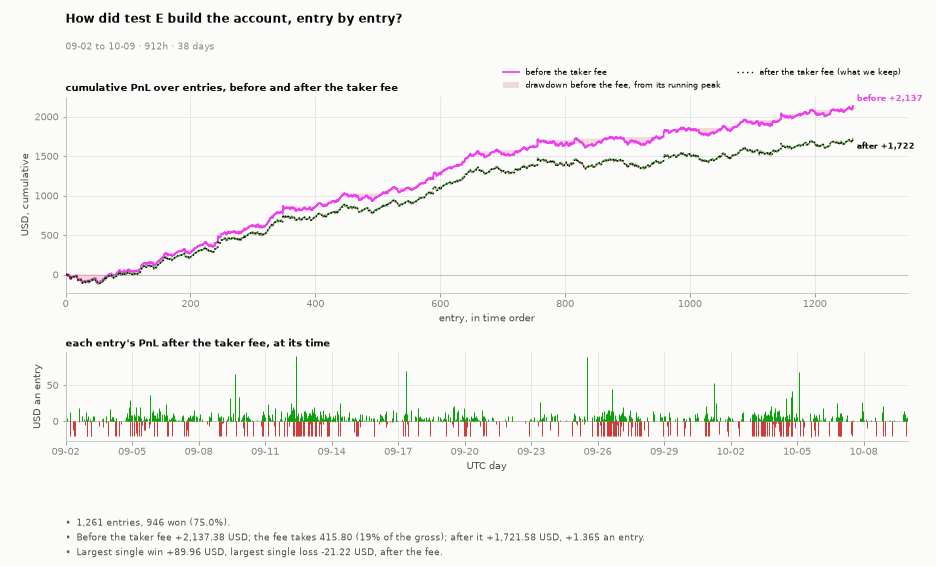

In [9]:
figstyle.show(TF.equity_fig(E_ALL, DAYS, question="How did test E build the account, entry by entry?"), "fig:s3-e-equity", FIGURES)

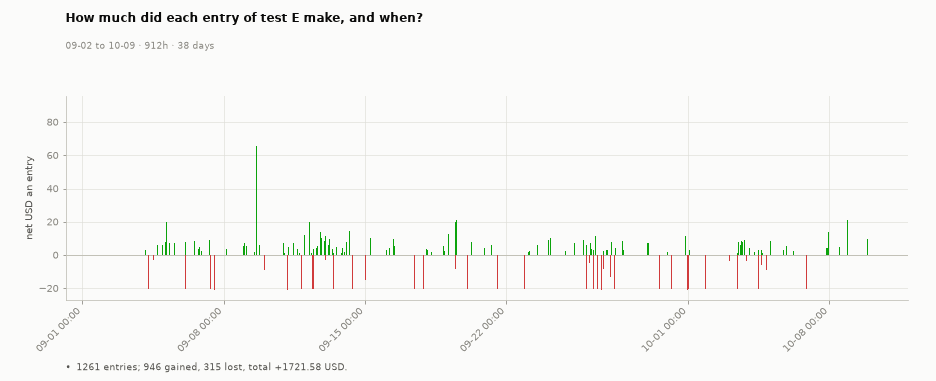

In [10]:
figstyle.show(TF.trade_pnl_fig(E_ALL, DAYS, question="How much did each entry of test E make, and when?"), "fig:s3-e-tradepnl", FIGURES)

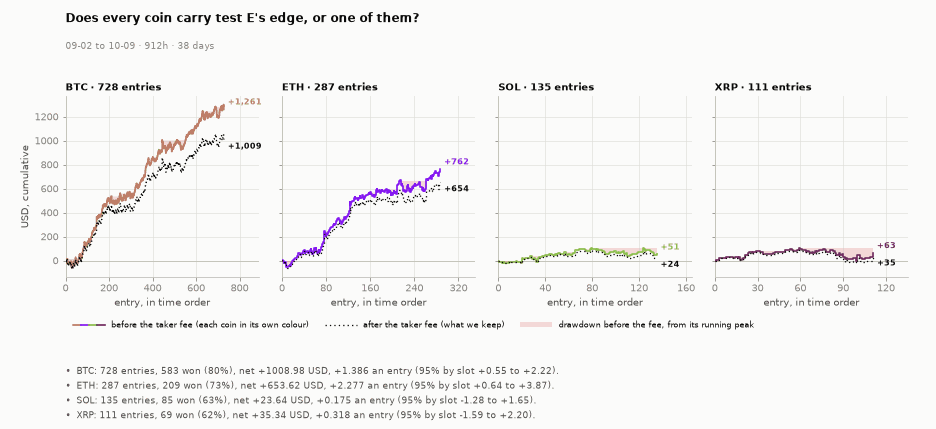

In [11]:
figstyle.show(TF.coin_panels_fig(E_ALL, DAYS, question="Does every coin carry test E's edge, or one of them?"), "fig:s3-e-coins", FIGURES)

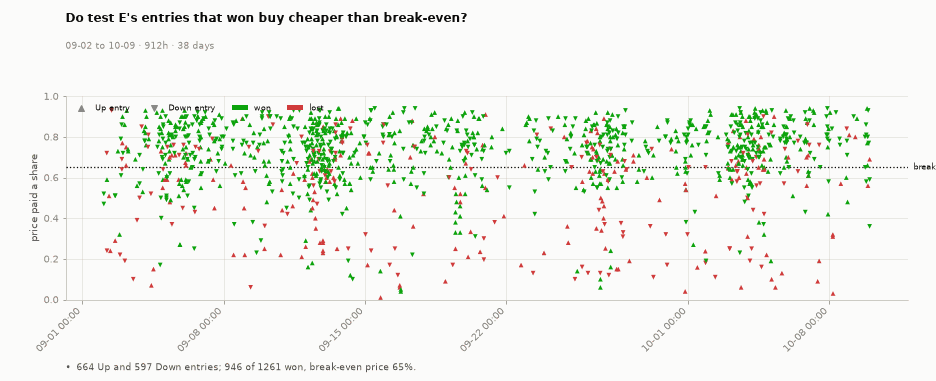

In [12]:
figstyle.show(TF.entry_price_fig(E_ALL, DAYS, be=float(S_E["breakeven"]), question="Do test E's entries that won buy cheaper than break-even?", s=22, edge=False), "fig:s3-e-entrypx", FIGURES)

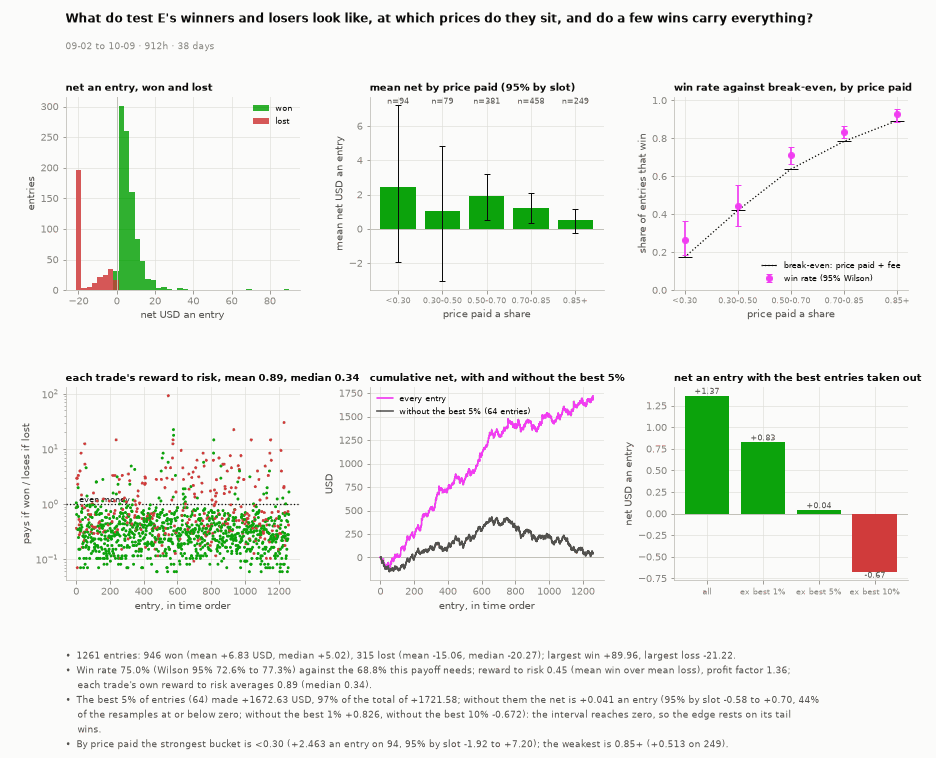

In [13]:
figstyle.show(TF.winloss_fig(E_ALL, DAYS, question="What do test E's winners and losers look like, at which prices do they sit, and do a few wins carry everything?"), "fig:s3-e-winloss", FIGURES)

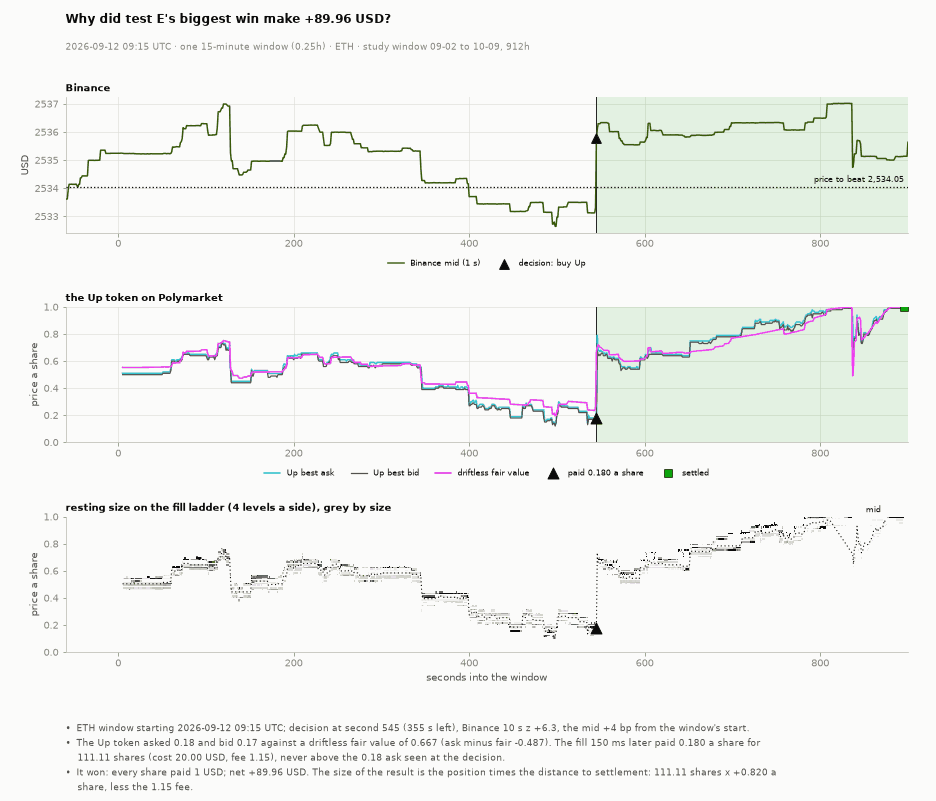

**Fill ladder at second 545 + 150 ms, ETH Up token: a buy of 20 USD of Up at no worse than the 0.18 ask seen at the decision; fair value 0.667; took 111.11 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,33.79,0.17,0.18,498.52,111.11,19.9998
2,30.00,0.16,0.19,536.00,0.00,0.0000
3,30.00,0.15,0.20,391.00,0.00,0.0000
4,165.00,0.14,0.22,210.00,0.00,0.0000


In [14]:
_i = int(np.argmax(E_ALL["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_ALL, _i, DAYS, question=f"Why did test E's biggest win make {E_ALL['net'][_i]:+.2f} USD?", usd=CLIP_USD), "fig:s3-e-bigwin", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_ALL, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**")); display(HTML(_df.round(4).to_html(index=False, border=0)))

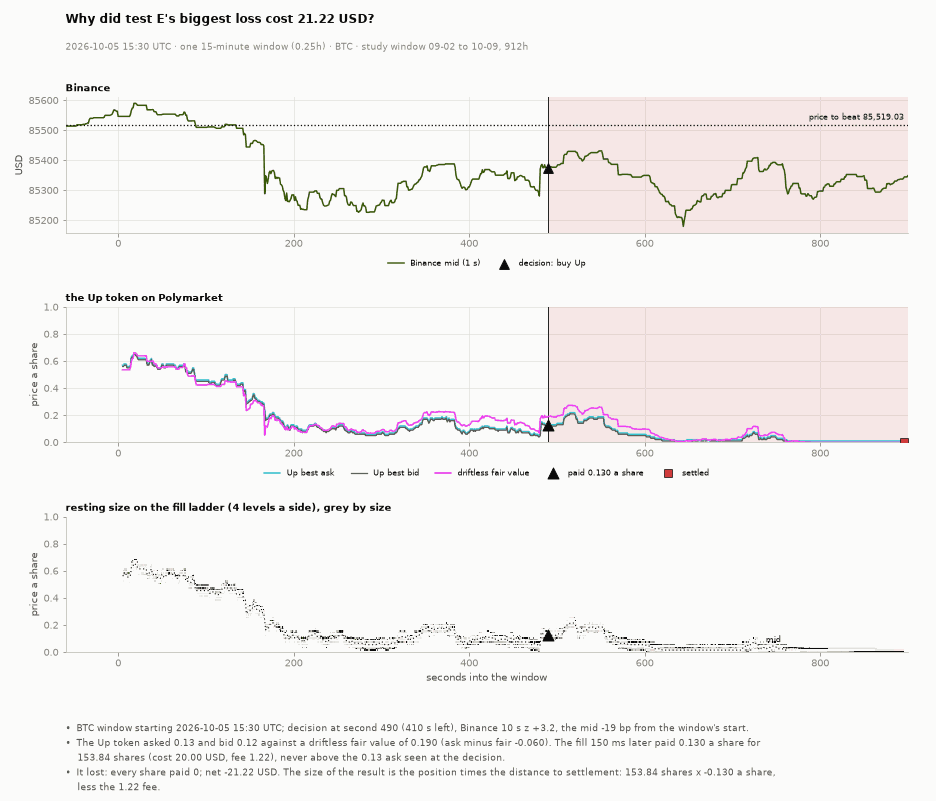

**Fill ladder at second 490 + 150 ms, BTC Up token: a buy of 20 USD of Up at no worse than the 0.13 ask seen at the decision; fair value 0.190; took 153.84 shares for 20.00 USD at risk.**

level,bid_size,bid,ask,ask_size,taken_shares,usd_at_risk
1,198.7100,0.12,0.13,368.52,153.84,19.9992
2,1274.0000,0.11,0.14,742.00,0.00,0.0000
3,1866.2100,0.10,0.15,1517.96,0.00,0.0000
4,5324.1201,0.09,0.16,7179.00,0.00,0.0000


In [15]:
_i = int(np.argmin(E_ALL["net"]))
figstyle.show(TF.anatomy_fig(TAB, E_ALL, _i, DAYS, question=f"Why did test E's biggest loss cost {-E_ALL['net'][_i]:.2f} USD?", usd=CLIP_USD), "fig:s3-e-bigloss", FIGURES)
_df, _cap = TF.ladder_table(TAB, E_ALL, _i, usd=CLIP_USD)
display(Markdown("**" + _cap + "**")); display(HTML(_df.round(4).to_html(index=False, border=0)))

### How the tuning works, in plain words

We split the 38 days into weeks by date: 09-02 to 09-08, 09-09 to 09-15, 09-16 to 09-22, 09-23 to 09-29, 09-30 to 10-06 and 10-07 to 10-09 (three days). From
the second week on, we pick the best setting (the stale window in seconds, the stale definition, the discount to fair value, the fill price limit) using ONLY
the weeks before it, then trade that setting on the week itself. Week one is only ever chosen on, never traded. Two questions follow.

1. **Is the pick the same week after week?** If the weeks before 09-09 say "3 seconds" and the weeks before 09-16 say "10 seconds", the data is not telling us
   one number; a real setting gets picked again and again. We count how many of the five picks choose the same stale window. PASS: at least 4 of 5 agree.
2. **Does the week a pick is traded on agree with the weeks it was chosen from?** The pick was made without that week, so its result there is honest. We put
   side by side what the pick earned on its choosing weeks (in-sample) and on the week it was then traded on (out-of-sample), without the best 5% of entries
   each time. Agree: the out-of-sample number is above zero and inside the in-sample number's 95% interval. Collapse: the choosing weeks fooled us. PASS: at
   least 4 of 5 weeks agree.

Beside both, the money question: over the 31 traded days (09-09 to 10-09), does the tuned rule beat test E as built (3 s, definition (a), 5 c, the ask seen)?
If it does not, tuning added nothing.

How a pick is made on its choosing weeks: every setting is scored by its net an entry without the best 5%; each score is averaged with the scores of the
neighbouring stale windows (same definition, discount and limit), so a lone lucky window cannot win; settings with fewer than `TUNE_N_MIN` entries are
skipped; the highest wins, a tie going to the shorter window.

### S3.2 · The surface on every seated day

**In one line:** every setting on all 38 days at once, a map of where the rule earns; it chooses nothing, because it has seen every day.

The second pass keeps only what the thesis gives a mechanism: how long the book has not moved (the window n), what "not moved" means (the three
definitions), how far under fair value the ask must sit (the discount to fair value: 3, 5 or 8 cents) and how high the order may pay (the ask seen, or our edge price). Everything else stays at
E's levels. The surface reads every cell on every seated day: it describes and chooses nothing; the walk-forward in S3.3 does the choosing. The first pass's
grid, sweep and figures are in git (`ce8039d9`).

  54 of 162 cells run


  108 of 162 cells run


  162 of 162 cells run


162 cells run and read in 67s; the plateau centre on every day: c6|th0.05|edge


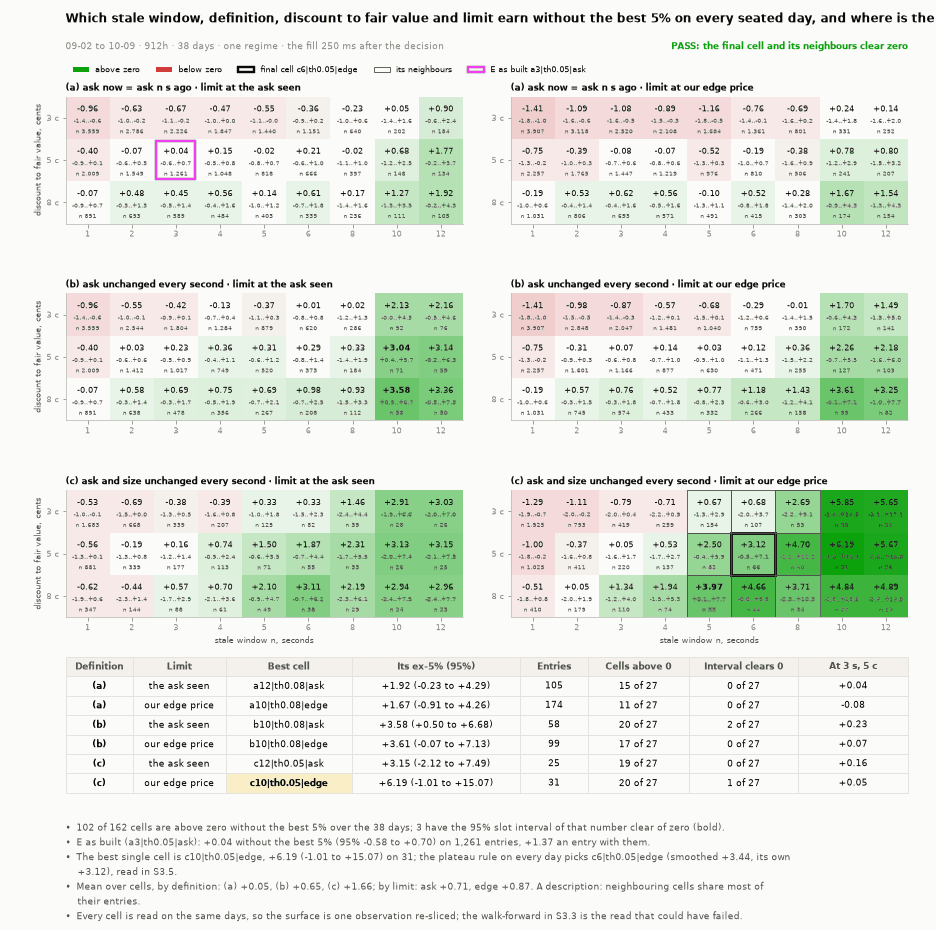

In [16]:
_t = time.time()
TUNE = ST.run_tune(CAND, TAB, TUNE_CELLS, log=print)
assert _same(TUNE[CFG_E["name"]], E_ALL), "the grid's E cell is not E"
SURF = {c_["name"]: ST.stats5(TUNE[c_["name"]]) for c_ in TUNE_CELLS}
FINAL_RANK = ST.choose_plateau(TUNE, TUNE_CELLS, ALL_IDX, TUNE_N_MIN, TUNE_LEVELS)
FINAL_ROW = FINAL_RANK[0]
CFG = FINAL_ROW["cfg"]
FINAL_IS_E = CFG["name"] == CFG_E["name"]
TUNE_SECONDS = time.time() - _t
SURF_DF = pd.DataFrame([dict(cell=c_["name"], definition=c_["kind"], n_s=c_["n"], theta=c_["theta"], limit=c_["limit"], entries=SURF[c_["name"]]["n"], per=SURF[c_["name"]]["per"],
                             ex5=SURF[c_["name"]]["per_ex_top5"], ex5_lo=SURF[c_["name"]]["per_ex_top5_lo"], ex5_hi=SURF[c_["name"]]["per_ex_top5_hi"]) for c_ in TUNE_CELLS])
_fb = ST.block_names(TUNE_CELLS, CFG, TUNE_LEVELS)
PLATEAU_OK = bool(_fb) and all(np.isfinite(SURF[x_]["per_ex_top5"]) and SURF[x_]["per_ex_top5"] > 0 for x_ in [CFG["name"], *_fb])
print(f"{len(TUNE):,} cells run and read in {TUNE_SECONDS:.0f}s; the plateau centre on every day: {CFG['name']}")
_e, _best = SURF[CFG_E["name"]], SURF_DF.sort_values("ex5", ascending=False).iloc[0]
_bk = SURF_DF.groupby("definition")["ex5"].mean()
_bl = SURF_DF.groupby("limit")["ex5"].mean()
_notes = [f"{int((SURF_DF.ex5 > 0).sum())} of {len(SURF_DF)} cells are above zero without the best 5% over the {len(DAYS)} days; {int((SURF_DF.ex5_lo > 0).sum())} have the 95% slot interval of that number clear of zero (bold).",
          f"E as built ({CFG_E['name']}): {sgn(_e['per_ex_top5'])} without the best 5% (95% {sgn(_e['per_ex_top5_lo'])} to {sgn(_e['per_ex_top5_hi'])}) on {_e['n']:,} entries, {sgn(_e['per'])} an entry with them.",
          f"The best single cell is {_best.cell}, {sgn(_best.ex5)} ({sgn(_best.ex5_lo)} to {sgn(_best.ex5_hi)}) on {int(_best.entries):,}; the plateau rule on every day picks {CFG['name']} "
          f"(smoothed {sgn(FINAL_ROW['smoothed'])}, its own {sgn(FINAL_ROW['score'])}), " + ("which is E as built." if FINAL_IS_E else "read in S3.5."),
          "Mean over cells, by definition: " + ", ".join(f"({k_}) {v_:+.2f}" for k_, v_ in _bk.items()) + "; by limit: " + ", ".join(f"{k_} {v_:+.2f}" for k_, v_ in _bl.items())
          + ". A description: neighbouring cells share most of their entries.",
          "Every cell is read on the same days, so the surface is one observation re-sliced; the walk-forward in S3.3 is the read that could have failed."]
figstyle.show(ST.surface_all_fig(SURF, TUNE_CELLS, CFG_E["name"], CFG["name"], WIN, _notes, TUNE_LEVELS), "fig:s3-surface", FIGURES)

### S3.3 · The walk-forward: every week out of sample once

**In one line:** the solid and dotted lines are the 31 days from 09-09 to 10-09, each week traded with the setting chosen before it; beside them, E as built
(3 s) on the same days. If the tuned line does not beat the built line out of sample, tuning added nothing (gate G3).

Weeks by day index (the last is short). For each week from the second, the plateau rule chooses on every week before it (an expanding window) and the
chosen cell trades that week alone; the first week is never scored out of sample. The rule: score each cell by its net an entry without the best 5% on the
choosing weeks, smooth it along the window (the mean of the cell and its adjacent windows at the same definition, discount and limit), keep the cells with at
least `TUNE_N_MIN` entries, take the highest; a tie goes to the smaller window. "E tuned" is the record those choices make, every day scored by a cell chosen
without it, read beside E as built and rule A on the same days.

**Each traded week's pick and its three runners-up**, scored on the choosing weeks only (rank 1 is the pick)

traded_week,chosen_on,rank,setting,entries,ex5,smoothed,qualifies
09-09 to 09-15,09-02 to 09-08,1,c1|th0.08|edge,87,2.098,3.141,True
09-09 to 09-15,09-02 to 09-08,2,a8|th0.05|ask,73,1.663,2.693,True
09-09 to 09-15,09-02 to 09-08,3,c1|th0.08|ask,72,1.853,2.130,True
09-09 to 09-15,09-02 to 09-08,4,a6|th0.08|edge,83,1.604,1.872,True
09-16 to 09-22,09-02 to 09-15,1,c3|th0.08|edge,63,3.716,3.388,True
09-16 to 09-22,09-02 to 09-15,2,a10|th0.08|ask,60,3.394,2.836,True
09-16 to 09-22,09-02 to 09-15,3,a12|th0.05|ask,69,2.845,2.750,True
09-16 to 09-22,09-02 to 09-15,4,a8|th0.08|ask,115,1.850,2.568,True
09-23 to 09-29,09-02 to 09-22,1,b10|th0.08|edge,71,4.033,3.941,True
09-23 to 09-29,09-02 to 09-22,2,a12|th0.08|ask,70,3.534,3.442,True


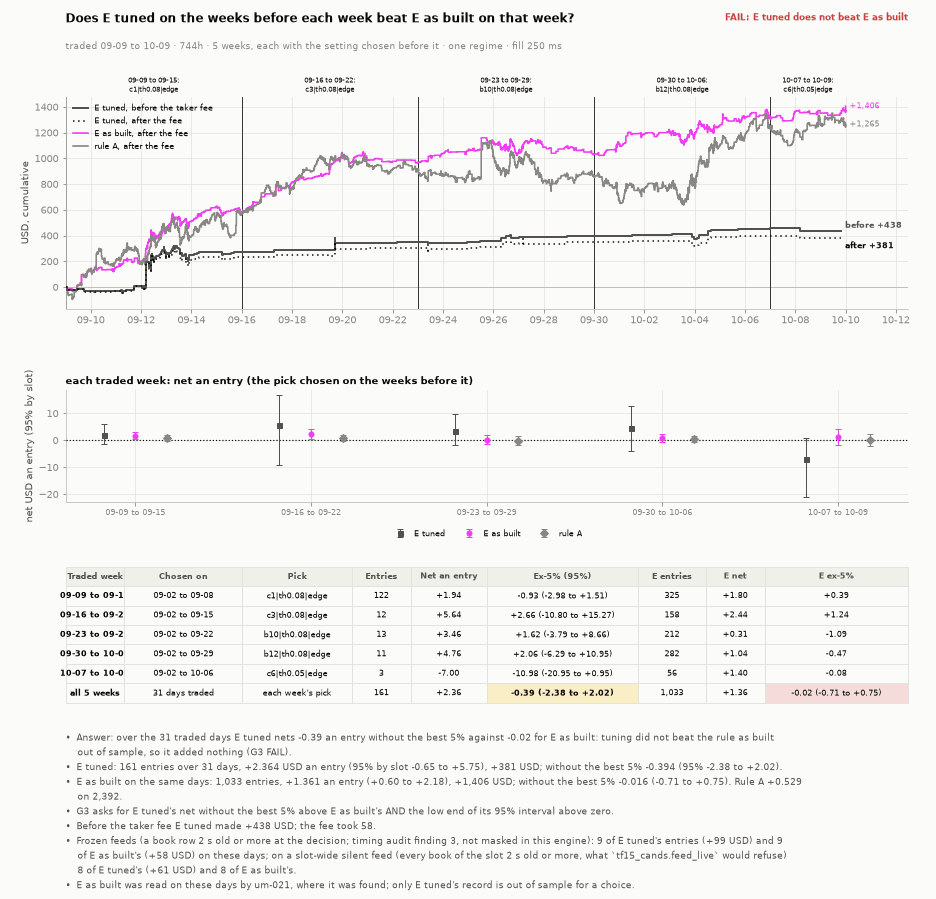

In [17]:
WF = ST.walk_forward(TUNE, TUNE_CELLS, len(DAYS), WEEK, TUNE_N_MIN, TUNE_LEVELS, e_name=CFG_E["name"])
OOS_IDX = WF["oos_idx"]
OOS_DAYS = [DAYS[i_] for i_ in OOS_IDX]
ENT = WF["record"]
REC_E, REC_A = ST.by_days(E_ALL, OOS_IDX), ST.by_days(A_ALL, OOS_IDX)
TS, TS_E, TS_A = ST.stats5(ENT), ST.stats5(REC_E), ST.stats5(REC_A)
WIN_WF = f"traded {OOS_DAYS[0][5:]} to {OOS_DAYS[-1][5:]} · {24 * len(OOS_DAYS):,}h · {len(WF['folds'])} weeks, each with the setting chosen before it · one regime · fill {LAT_MS} ms"
WK = lambda f_: ST.week_name(DAYS, f_["out_idx"])
G_WALK = bool(TS.get("n") and TS_E.get("n") and TS["per_ex_top5"] > TS_E["per_ex_top5"] and TS["per_ex_top5_lo"] > 0)
_rows = [dict(traded_week=WK(f_), chosen_on=ST.week_name(DAYS, f_["choose_idx"]), rank=j_ + 1, setting=r_["cfg"]["name"], entries=r_["n"],
              ex5=r_["score"], smoothed=r_["smoothed"], qualifies=r_["eligible"]) for f_ in WF["folds"] for j_, r_ in enumerate(f_["rank"])]
display(Markdown("**Each traded week's pick and its three runners-up**, scored on the choosing weeks only (rank 1 is the pick)"))
display(HTML(pd.DataFrame(_rows).round(3).to_html(index=False, border=0)))
OLD_WF = {k_: ST.old_book(TAB, e_) for k_, e_ in (("tuned", ENT), ("E", REC_E))}
_notes = [f"Answer: over the {len(OOS_DAYS)} traded days E tuned nets {sgn(TS['per_ex_top5'])} an entry without the best 5% against {sgn(TS_E['per_ex_top5'])} for E as built: "
          + ("tuning beat the rule as built out of sample (G3 PASS)." if G_WALK else "tuning did not beat the rule as built out of sample, so it added nothing (G3 FAIL)."),
          f"E tuned: {TS['n']:,} entries over {len(OOS_DAYS)} days, {sgn(TS['per'], 3)} USD an entry (95% by slot {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}), {sgn(TS['net'], 0)} USD; "
          f"without the best 5% {sgn(TS['per_ex_top5'], 3)} (95% {sgn(TS['per_ex_top5_lo'])} to {sgn(TS['per_ex_top5_hi'])}).",
          f"E as built on the same days: {TS_E['n']:,} entries, {sgn(TS_E['per'], 3)} an entry ({sgn(TS_E['per_lo'])} to {sgn(TS_E['per_hi'])}), {sgn(TS_E['net'], 0)} USD; without the best 5% "
          f"{sgn(TS_E['per_ex_top5'], 3)} ({sgn(TS_E['per_ex_top5_lo'])} to {sgn(TS_E['per_ex_top5_hi'])}). Rule A {sgn(TS_A['per'], 3)} on {TS_A['n']:,}.",
          "G3 asks for E tuned's net without the best 5% above E as built's AND the low end of its 95% interval above zero.",
          f"Before the taker fee E tuned made {sgn(float(ENT['gross'].sum()), 0)} USD; the fee took {float(ENT['fee'].sum()):,.0f}.",
          f"Frozen feeds (a book row 2 s old or more at the decision; timing audit finding 3, not masked in this engine): {OLD_WF['tuned'][0]} of E tuned's entries ({sgn(OLD_WF['tuned'][2], 0)} USD) "
          f"and {OLD_WF['E'][0]} of E as built's ({sgn(OLD_WF['E'][2], 0)} USD) on these days"
          + (f"; on a slot-wide silent feed (every book of the slot 2 s old or more, what `tf15_cands.feed_live` would refuse) {silent(ENT)[0]} of E tuned's ({sgn(silent(ENT)[1], 0)} USD) and {silent(REC_E)[0]} of E as built's."
             if FEED_LIVE is not None else "."),
          "E as built was read on these days by um-021, where it was found; only E tuned's record is out of sample for a choice."]
figstyle.show(ST.walk_fig({"tuned": ("E tuned", ENT), "E": ("E as built", REC_E), "A": ("rule A", REC_A)}, WF, DAYS, _notes, WIN_WF, G_WALK), "fig:s3-walk", FIGURES)

### S3.4 · Is the choice stable?

**In one line:** for each traded week, did the weeks before it pick the same stale window as the other weeks did (question 1, gate G4), and did the week
itself then earn what the choosing weeks promised (question 2, gate G15)?

Each panel is one traded week: along the stale window, for the pick's definition, discount and limit, the score on the choosing weeks (raw, and smoothed as
the rule reads it) and what the traded week then realised at every window.

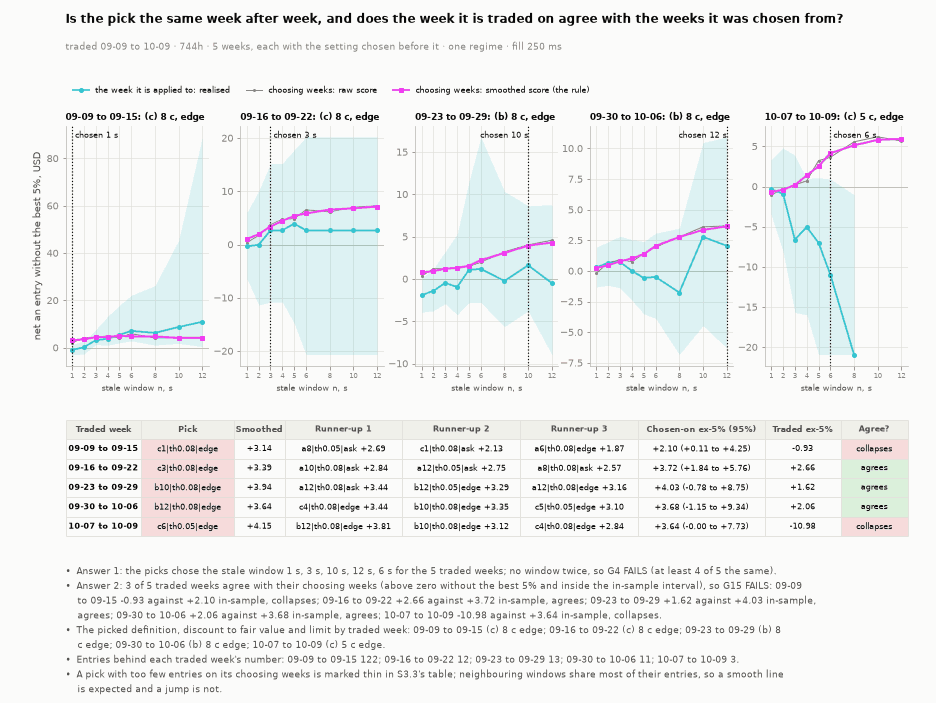

In [18]:
NS_CHOSEN = [f_["chosen"]["cfg"]["n"] for f_ in WF["folds"]]
N_MODE, N_MODE_COUNT = Counter(NS_CHOSEN).most_common(1)[0]
G_STABLE = N_MODE_COUNT >= STABLE_MIN
N_AGREE = sum(f_["agree"] for f_ in WF["folds"])
G_AGREE = N_AGREE >= STABLE_MIN
_here = [next(c_ for c_ in f_["curve"] if c_["n"] == f_["chosen"]["cfg"]["n"])["week"] for f_ in WF["folds"]]
_notes = ["Answer 1: the picks chose the stale window " + ", ".join(f"{f_['chosen']['cfg']['n']} s" for f_ in WF["folds"]) + f" for the {len(WF['folds'])} traded weeks; "
          + (f"{N_MODE} s {N_MODE_COUNT} times" if N_MODE_COUNT > 1 else "no window twice") + f", so G4 {'PASSES' if G_STABLE else 'FAILS'} (at least {STABLE_MIN} of {len(NS_CHOSEN)} the same).",
          f"Answer 2: {N_AGREE} of {len(WF['folds'])} traded weeks agree with their choosing weeks (above zero without the best 5% and inside the in-sample interval), so G15 "
          + f"{'PASSES' if G_AGREE else 'FAILS'}: " + "; ".join(f"{WK(f_)} {sgn(f_['s'].get('per_ex_top5'))} against {sgn(f_['s_in'].get('per_ex_top5'))} in-sample, {'agrees' if f_['agree'] else 'collapses'}" for f_ in WF["folds"]) + ".",
          "The picked definition, discount to fair value and limit by traded week: " + "; ".join(f"{WK(f_)} ({f_['chosen']['cfg']['kind']}) {f_['chosen']['cfg']['theta'] * 100:.0f} c {f_['chosen']['cfg']['limit']}" for f_ in WF["folds"]) + ".",
          "Entries behind each traded week's number: " + "; ".join(f"{WK(f_)} {h_.get('n', 0):,}" for f_, h_ in zip(WF["folds"], _here)) + ".",
          "A pick with too few entries on its choosing weeks is marked thin in S3.3's table; neighbouring windows share most of their entries, so a smooth line is expected and a jump is not."]
figstyle.show(ST.stable_fig(WF, DAYS, _notes, WIN_WF), "fig:s3-stable", FIGURES)

### S3.5 · The final cell

**In one line:** the setting the same rule picks from all 38 days (what a forward read would freeze), judged by the walk-forward record, not by its own days.

The plateau rule applied to every seated day picks the cell a forward read would freeze. Its numbers on those days are in-sample (it was chosen on them); its
honest read is the walk-forward record of S3.3, the same rule run without sight of each week. Beside it: the latency ladder (tables seated at other delays and
whole seconds added to the 250 ms table) and the fee sweep, against E as built; S4.2 and S4.3 draw both in full.

final cell read in 79s; seated tables [150, 250, 500, 1000]


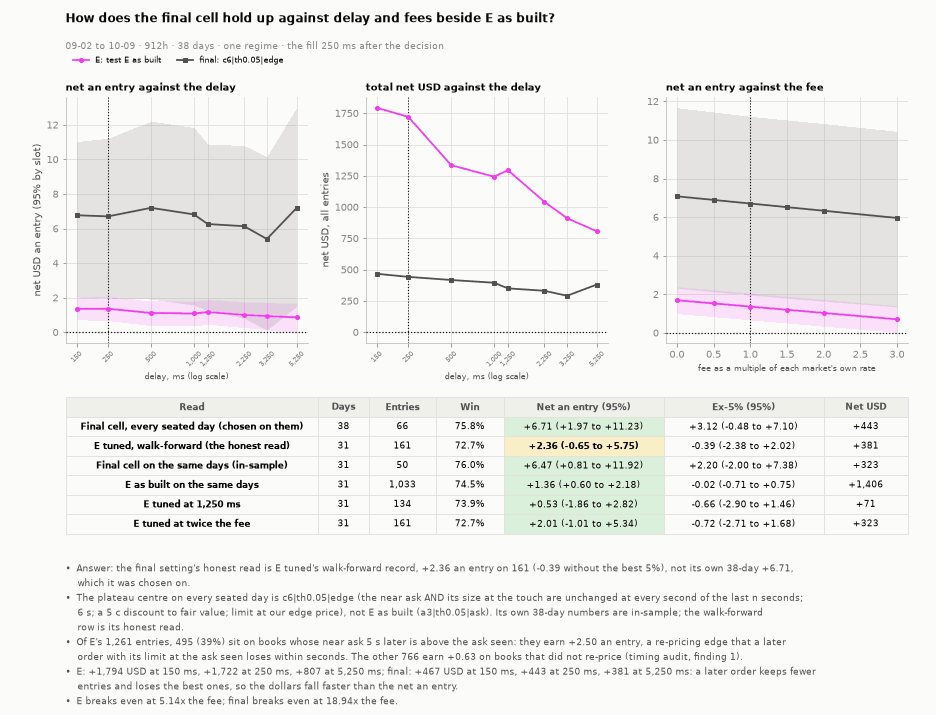

In [19]:
import gc
_t = time.time()
CELL_ALL = TUNE[CFG["name"]]
S_CELL = ST.stats5(CELL_ALL)
REC_F = ST.by_days(CELL_ALL, OOS_IDX)
TS_F = ST.stats5(REC_F)
WF_1S = ST.stats(ST.wf_variant(CAND, TAB, WF, delay_k=1))
WF_FEE2 = ST.stats(ST.wf_variant(CAND, TAB, WF, fee_mult=2.0))
SH, DSR = ST.deflated_record(TUNE, ENT)
LAT_TABS = {LAT_MS: TAB}
LAT_MISSING = {}
for ms_ in (150, 500, 1000):
    miss_ = [d_ for d_ in DAYS if RUNNER.seated(d_, ms_) is None]
    if miss_:
        LAT_MISSING[ms_] = miss_
        continue
    LAT_TABS[ms_] = B.Tab(DAYS, fill_ms=ms_)
LAT = {"E": ("E: test E as built", ST.latency_rows(CAND, LAT_TABS, CFG_E, LAT_MS, EXTRA_S)), "cell": (f"final: {CFG['name']}", ST.latency_rows(CAND, LAT_TABS, CFG, LAT_MS, EXTRA_S))}
DELAY_E = {"E": ST.delay_entries(CAND, LAT_TABS, CFG_E, LAT_MS, EXTRA_S), "cell": ST.delay_entries(CAND, LAT_TABS, CFG, LAT_MS, EXTRA_S)}     # S4.2's paths
LAT_SEATED = sorted(LAT_TABS)
for ms_ in [m_ for m_ in LAT_TABS if m_ != LAT_MS]:
    del LAT_TABS[ms_]
gc.collect()
COSTS = {"E": ("E: test E as built", ST.cost_read(CAND, TAB, CFG_E, ALL_IDX, FEE_MULTS, SLIPS)), "cell": (f"final: {CFG['name']}", ST.cost_read(CAND, TAB, CFG, ALL_IDX, FEE_MULTS, SLIPS))}
REPRICE = {"E": ST.repricing_split(TAB, E_ALL), "cell": ST.repricing_split(TAB, CELL_ALL)}
print(f"final cell read in {time.time() - _t:.0f}s; seated tables {LAT_SEATED}")
_ci = lambda s_: f"{sgn(s_.get('per_ex_top5'))} ({sgn(s_.get('per_ex_top5_lo'))} to {sgn(s_.get('per_ex_top5_hi'))})"
_line = lambda lab_, nd_, s_: [lab_, f"{nd_}", f"{s_.get('n', 0):,}", pct(s_.get("win", float("nan"))), f"{sgn(s_.get('per'))} ({sgn(s_.get('per_lo'))} to {sgn(s_.get('per_hi'))})", _ci(s_), sgn(s_.get("net", float("nan")), 0)]
FINAL_ROWS = [_line("Final cell, every seated day (chosen on them)", len(DAYS), S_CELL), _line("E tuned, walk-forward (the honest read)", len(OOS_DAYS), TS),
              _line("Final cell on the same days (in-sample)", len(OOS_DAYS), TS_F), _line("E as built on the same days", len(OOS_DAYS), TS_E),
              _line("E tuned at 1,250 ms", len(OOS_DAYS), WF_1S), _line("E tuned at twice the fee", len(OOS_DAYS), WF_FEE2)]
_rp = REPRICE["E"]
_n_rest = _rp["same"][0] + _rp["lower"][0]
_notes = [f"Answer: the final setting's honest read is E tuned's walk-forward record, {sgn(TS['per'])} an entry on {TS['n']:,} ({sgn(TS['per_ex_top5'])} without the best 5%), "
          f"not its own {len(DAYS)}-day {sgn(S_CELL['per'])}, which it was chosen on.",
          ("The plateau centre on every seated day is E as built: the tuning confirms the brief's 3 s, definition (a), a 5 c discount to fair value and the ask-seen limit."
           if FINAL_IS_E else f"The plateau centre on every seated day is {CFG['name']} ({C.STALE_DEFS[CFG['kind']].split('(')[0].strip()}; {CFG['n']} s; a {CFG['theta'] * 100:.0f} c discount to fair value; limit at {ST.LIMIT_NAME[CFG['limit']]}), not E as built ({CFG_E['name']}).")
          + f" Its own {len(DAYS)}-day numbers are in-sample; the walk-forward row is its honest read.",
          f"Of E's {S_E['n']:,} entries, {_rp['higher'][0]:,} ({_rp['higher'][0] / max(S_E['n'], 1):.0%}) sit on books whose near ask 5 s later is above the ask seen: they earn {sgn(_rp['higher'][1])} an entry, "
          f"a re-pricing edge that a later order with its limit at the ask seen loses within seconds. The other {_n_rest:,} earn {sgn((_rp['same'][2] + _rp['lower'][2]) / max(_n_rest, 1))} on books that did not re-price (timing audit, finding 1).",
          "; ".join(f"{t_.split(':')[0]}: {sgn(rr_[0]['total'], 0)} USD at {rr_[0]['ms']:,} ms, {sgn(next(r_['total'] for r_ in rr_ if r_['ms'] == LAT_MS), 0)} at {LAT_MS} ms, {sgn(rr_[-1]['total'], 0)} at {rr_[-1]['ms']:,} ms" for t_, rr_ in LAT.values())
          + ": a later order keeps fewer entries and loses the best ones, so the dollars fall faster than the net an entry.",
          "; ".join(f"{t_.split(':')[0]} breaks even at {c_['be_mult']:.2f}x the fee" for t_, c_ in COSTS.values()) + "."]
figstyle.show(ST.final_fig({k_: LAT[k_] for k_ in ("E", "cell")}, COSTS, FINAL_ROWS, ["Read", "Days", "Entries", "Win", "Net an entry (95%)", "Ex-5% (95%)", "Net USD"], _notes, WIN, LAT_MS),
              "fig:s3-final", FIGURES)

In [20]:
# ---- the live spec of the final cell, for the paper run (tf15_live.to_spec) ----
import json
import tf15_live as LV
RULE_LIVE, WHY_NO_LIVE = ST.live_rule(CFG, CLIP_USD)
if RULE_LIVE is not None and CFG["limit"] == "ask":
    SPEC = LV.to_spec(RULE_LIVE)
    assert LV.to_spec(LV.from_spec(json.loads(json.dumps(SPEC)))) == SPEC, "the spec does not round-trip"
    display(Markdown("**Live spec of the final cell** (round-trips through `tf15_live.from_spec`)\n\n```json\n" + json.dumps(SPEC, indent=1) + "\n```\n\n" + LV.explain(RULE_LIVE)))
else:
    if CFG["limit"] != "ask":
        WHY_NO_LIVE = (WHY_NO_LIVE + "; " if WHY_NO_LIVE else "") + "the edge-price limit (fair value less the discount) is not a parameter of `tf15_live.LayeredRule`, which pays at most the ask seen"
    SPEC = dict(LV.to_spec(LV.LayeredRule(L=CFG["L"], z_min=CFG["z_min"], theta=CFG["theta"], band=C.STALE_BANDS[CFG["band"]], t_min=CFG["t_min"], stale_s=CFG["n"], usd=CLIP_USD, name=CFG["name"])),
                stale_kind=CFG["kind"], fill_limit=CFG["limit"])
    display(Markdown("**Live spec of the final cell, with its stale definition and fill limit named** (`stale_kind`, `fill_limit`)\n\n```json\n" + json.dumps(SPEC, indent=1) + f"\n```\n\n{WHY_NO_LIVE}."))

**Live spec of the final cell, with its stale definition and fill limit named** (`stale_kind`, `fill_limit`)

```json
{
 "rule": "buy_near_layered",
 "version": 1,
 "L": 10,
 "z_min": 3.0,
 "theta": 0.05,
 "band": [
  0.0,
  1.0
 ],
 "t_min": 300.0,
 "usd": 20.0,
 "exits": [],
 "name": "c6|th0.05|edge",
 "time": null,
 "hour": null,
 "spread": null,
 "gap": null,
 "rsi": null,
 "level": null,
 "flow": null,
 "coin": null,
 "onset": false,
 "slot_one": false,
 "stale_s": 6,
 "stale_kind": "c",
 "fill_limit": "edge"
}
```

definition (c) is not `LayeredRule.stale_s` (endpoints only); its live form needs `tf15_live` to read every second and the touch size; the edge-price limit (fair value less the discount) is not a parameter of `tf15_live.LayeredRule`, which pays at most the ask seen.

### S3.6 · The rules over time

**In one line:** the account after the fee, day by day: E tuned from 09-09 (each week traded with the setting chosen before it), the final setting, E as built
and rule A on every day. E tuned starts later, so its total is compared with E as built's on the same 31 days in the bullets, not with the line ends.

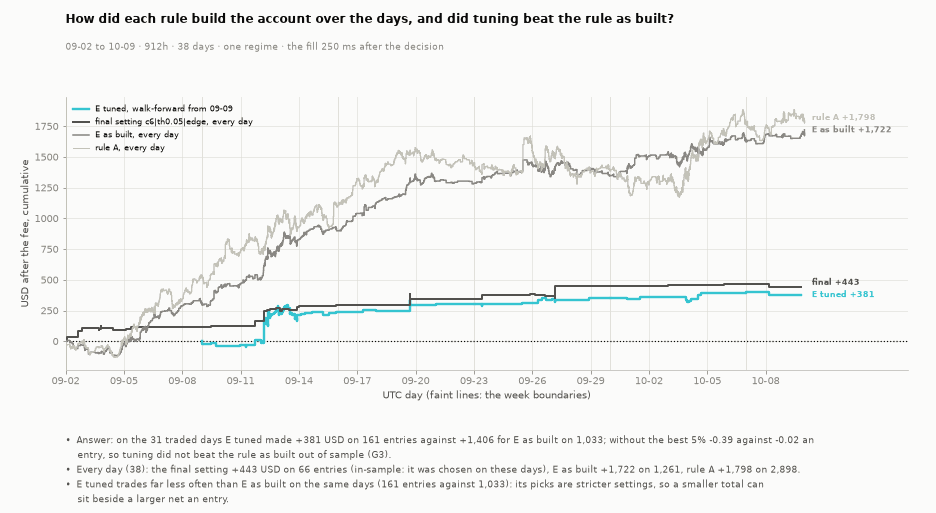

In [21]:
_tot = lambda e_: float(np.sum(e_["net"]))
_lines = [("E tuned, walk-forward from " + OOS_DAYS[0][5:], "E tuned", ENT, figstyle.IDENTITY["POLYMARKET"], 2.4, int(OOS_IDX[0])),
          (f"final setting {CFG['name']}, every day", "final", CELL_ALL, ST.INK2, 2.0, 0), ("E as built, every day", "E as built", E_ALL, ST.MUTED, 1.5, 0),
          ("rule A, every day", "rule A", A_ALL, N_AXIS, 1.3, 0)]
_notes = [f"Answer: on the {len(OOS_DAYS)} traded days E tuned made {sgn(TS['net'], 0)} USD on {TS['n']:,} entries against {sgn(TS_E['net'], 0)} for E as built on {TS_E['n']:,}; without the best 5% "
          f"{sgn(TS['per_ex_top5'])} against {sgn(TS_E['per_ex_top5'])} an entry, so tuning " + ("beat" if G_WALK else "did not beat") + " the rule as built out of sample (G3).",
          f"Every day ({len(DAYS)}): the final setting {sgn(_tot(CELL_ALL), 0)} USD on {S_CELL['n']:,} entries (in-sample: it was chosen on these days), E as built {sgn(_tot(E_ALL), 0)} on {S_E['n']:,}, "
          f"rule A {sgn(_tot(A_ALL), 0)} on {S_A['n']:,}.",
          f"E tuned trades far less often than E as built on the same days ({TS['n']:,} entries against {TS_E['n']:,}): its picks are stricter settings, so a smaller total can sit beside a larger net an entry."]
figstyle.show(ST.rules_paths_fig(_lines, DAYS, WF["weeks"], WIN, _notes), "fig:s3-paths", FIGURES)

## S4 · Robustness

On the final cell and on test E side by side. The final cell was chosen on every seated day, so its blocks and folds below are consistency checks; the
walk-forward record of S3.3 is its clean read.

### S4.1 · Out of sample and luck

The luck test is the random-burst null (`tf15_oos.random_burst`, the accounting audit's fix of 2026-10-11): the same count of entries per day and coin at
seconds that pass every condition of the cell except the burst (the discount to fair value, the band, the stale condition), bought at the ask seen. It asks whether the
burst's direction adds anything to a book that already passes the gate. The coin-flip side is printed as a reading only: it buys the far token, which sits
above its own fair value wherever the near one passes the gate, so it measures the price gate and cannot fail (the audit's finding 2).

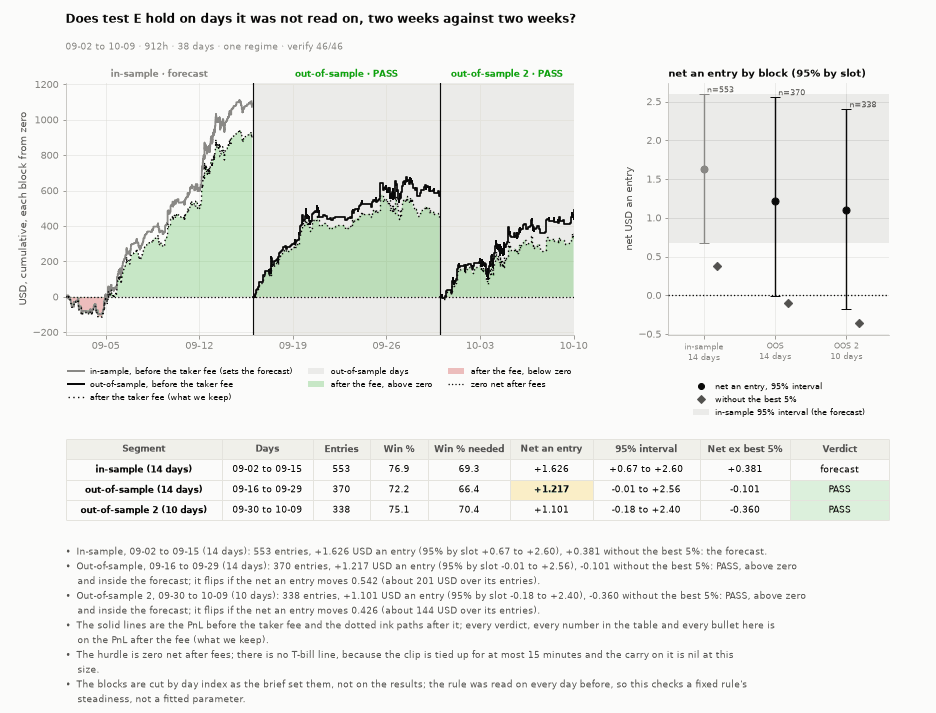

In [22]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = O.read_blocks(E_ALL, DAYS, N_IS, N_OOS)
OOS2W_E = _r
figstyle.show(OF.oos2w_fig(E_ALL, DAYS, _r, OF.block_notes(_r, O.MIN_N), "Does test E hold on days it was not read on, two weeks against two weeks?", WIN_), "fig:s4-e-oos2w", FIGURES)

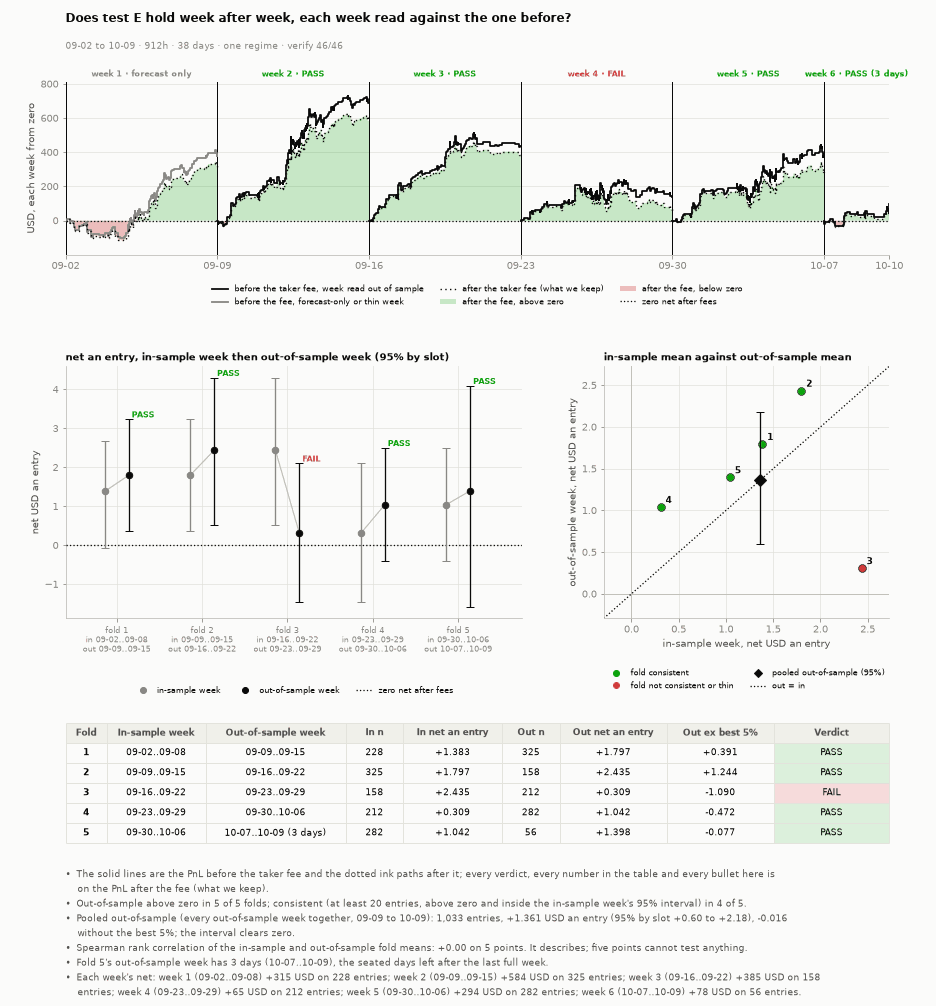

In [23]:
_f = O.read_folds(E_ALL, DAYS, WEEK)
FOLDS_E = _f
figstyle.show(OF.folds_fig(E_ALL, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), "Does test E hold week after week, each week read against the one before?", WIN_), "fig:s4-e-oosfolds", FIGURES)

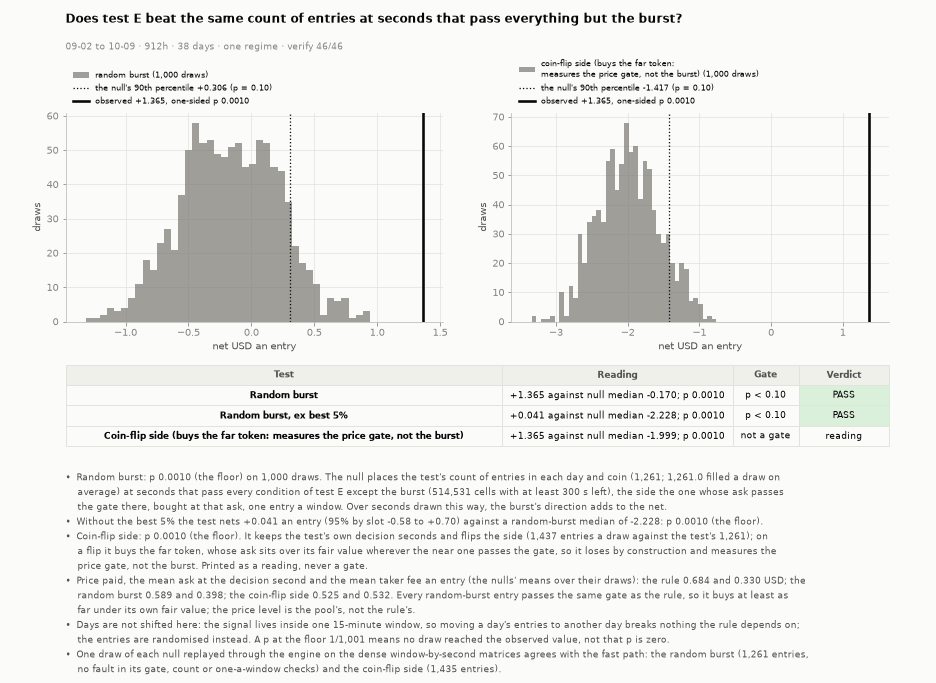

In [24]:
_s = ST.stats5(E_ALL)
_g, _tm, _m = CAND.gates(TAB, CFG_E), C.tmask(TAB, CFG_E["t_min"]), ST.burst_masks(TAB, CFG_E)
_rs = O.random_side(TAB, _g, _tm, usd=CLIP_USD, draws=N_DRAWS, seed=31)
_rb = O.random_burst(TAB, E_ALL, _m, "A", t_min=CFG_E["t_min"], usd=CLIP_USD, draws=N_DRAWS, seed=37)
_ok_s, _n_s = O.side_agrees(TAB, _g, _tm, usd=CLIP_USD)
_ag = O.burst_agrees(TAB, E_ALL, _m, "A", theta=CFG_E["theta"], t_min=CFG_E["t_min"], usd=CLIP_USD)
assert _ok_s and _ag["agree"] and not _ag["faults"], f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
_ask = O.ask_of(TAB, E_ALL)
_p = dict(burst=O.p_one_sided(_rb["per"], _s["per"]), burst_ex5=O.p_one_sided(_rb["ex5"], _s["per_ex_top5"]), side=O.p_one_sided(_rs["per"], _s["per"]), side_ex5=O.p_one_sided(_rs["ex5"], _s["per_ex_top5"]))
RAND_E = _p
_rows, _notes = OF.burst_rows("E", _s, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, CFG_E["t_min"], dict(burst=_ag, side=(_ok_s, _n_s)))
if CFG_E["limit"] != "ask":
    _notes.append("This cell's limit is our edge price; the null buys at the ask seen, so it fills a little less than the cell would.")
_nulls = [dict(name="random burst", null=_rb["per"], observed=_s["per"], p=_p["burst"]),
          dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=_s["per"], p=_p["side"])]
figstyle.show(OF.random_fig(_nulls, _rows, _notes, "Does test E beat the same count of entries at seconds that pass everything but the burst?", WIN_, colw=OF.BURST_COLW), "fig:s4-e-random", FIGURES)

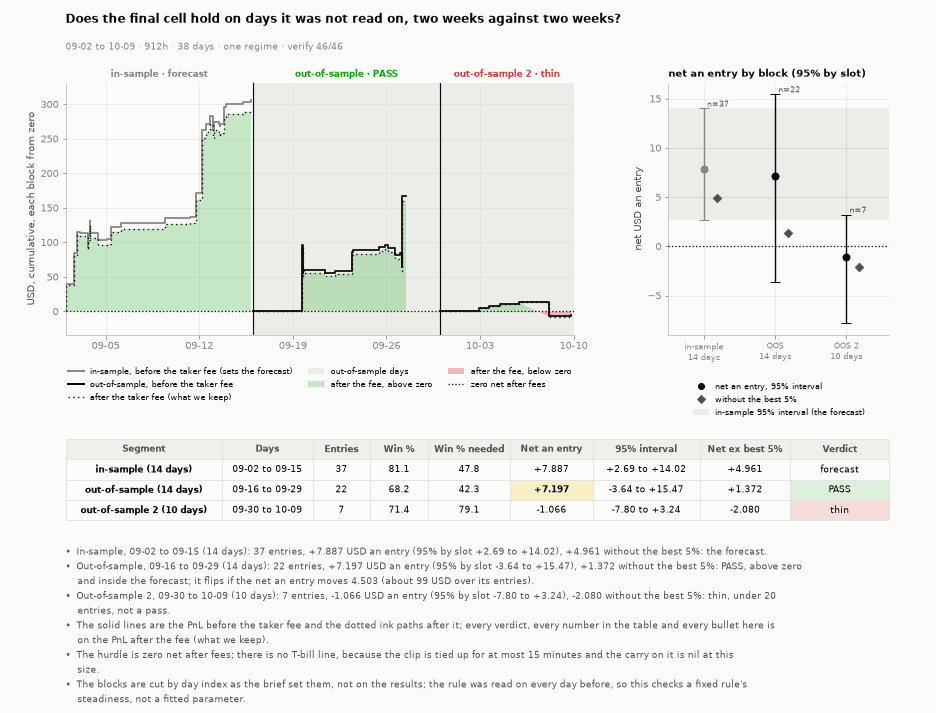

In [25]:
WIN_ = f"{DAYS[0][5:]} to {DAYS[-1][5:]} · {24 * len(DAYS):,}h · {len(DAYS)} days · one regime · verify {VERIFY_PASSED}/{VERIFY_TOTAL}"
_r = O.read_blocks(CELL_ALL, DAYS, N_IS, N_OOS)
OOS2W_CELL = _r
figstyle.show(OF.oos2w_fig(CELL_ALL, DAYS, _r, OF.block_notes(_r, O.MIN_N), "Does the final cell hold on days it was not read on, two weeks against two weeks?", WIN_), "fig:s4-cell-oos2w", FIGURES)

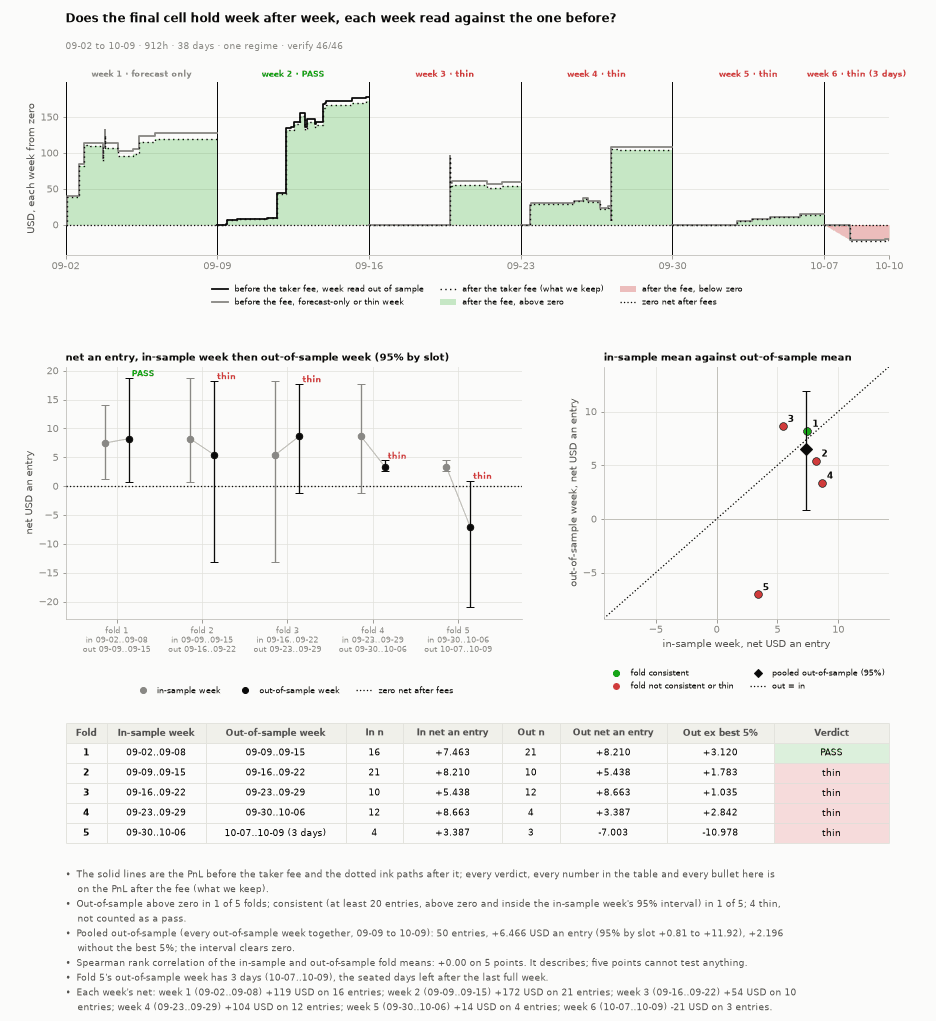

In [26]:
_f = O.read_folds(CELL_ALL, DAYS, WEEK)
FOLDS_CELL = _f
figstyle.show(OF.folds_fig(CELL_ALL, DAYS, _f, OF.fold_notes(_f, DAYS, WEEK, O.MIN_N), "Does the final cell hold week after week, each week read against the one before?", WIN_), "fig:s4-cell-oosfolds", FIGURES)

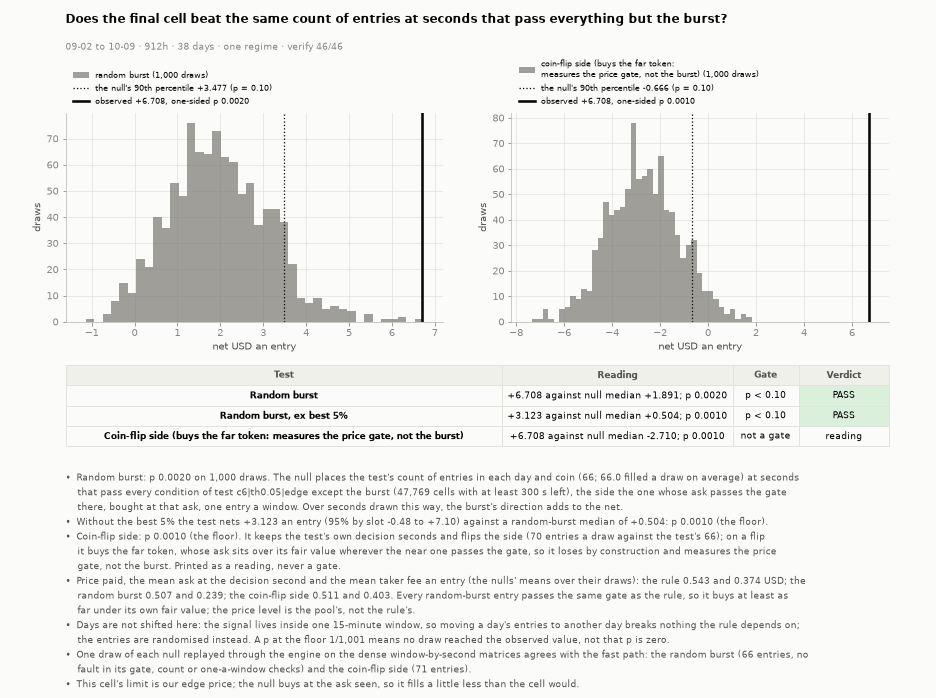

In [27]:
_s = ST.stats5(CELL_ALL)
_g, _tm, _m = CAND.gates(TAB, CFG), C.tmask(TAB, CFG["t_min"]), ST.burst_masks(TAB, CFG)
_rs = O.random_side(TAB, _g, _tm, usd=CLIP_USD, draws=N_DRAWS, seed=31)
_rb = O.random_burst(TAB, CELL_ALL, _m, "A", t_min=CFG["t_min"], usd=CLIP_USD, draws=N_DRAWS, seed=37)
_ok_s, _n_s = O.side_agrees(TAB, _g, _tm, usd=CLIP_USD)
_ag = O.burst_agrees(TAB, CELL_ALL, _m, "A", theta=CFG["theta"], t_min=CFG["t_min"], usd=CLIP_USD)
assert _ok_s and _ag["agree"] and not _ag["faults"], f"a randomised null disagrees with B.entries or breaks its own rules: {_ag}"
_ask = O.ask_of(TAB, CELL_ALL)
_p = dict(burst=O.p_one_sided(_rb["per"], _s["per"]), burst_ex5=O.p_one_sided(_rb["ex5"], _s["per_ex_top5"]), side=O.p_one_sided(_rs["per"], _s["per"]), side_ex5=O.p_one_sided(_rs["ex5"], _s["per_ex_top5"]))
RAND_CELL = _p
_rows, _notes = OF.burst_rows(CFG["name"], _s, _ask, _rb, _rs, _p, N_DRAWS, P_GATE, CFG["t_min"], dict(burst=_ag, side=(_ok_s, _n_s)))
if CFG["limit"] != "ask":
    _notes.append("This cell's limit is our edge price; the null buys at the ask seen, so it fills a little less than the cell would.")
_nulls = [dict(name="random burst", null=_rb["per"], observed=_s["per"], p=_p["burst"]),
          dict(name="coin-flip side (buys the far token:\nmeasures the price gate, not the burst)", null=_rs["per"], observed=_s["per"], p=_p["side"])]
figstyle.show(OF.random_fig(_nulls, _rows, _notes, "Does the final cell beat the same count of entries at seconds that pass everything but the burst?", WIN_, colw=OF.BURST_COLW), "fig:s4-cell-random", FIGURES)

In [28]:
# ---- E tuned's walk-forward record against the random-burst null, each fold on its own week with its own cell (gate G7) ----
_t = time.time()
REC_BURST = ST.record_burst(TAB, WF, draws=N_DRAWS, seed=41, usd=CLIP_USD)
P_REC_BURST = O.p_one_sided(REC_BURST["per"], TS["per"]) if TS.get("n") else float("nan")
display(Markdown(f"**E tuned's walk-forward record against the random-burst null** ({N_DRAWS:,} draws; each fold's count of entries per day and coin at its week's seconds that pass "
                 f"every condition of its cell but the burst; {time.time() - _t:.0f}s): the null's median {sgn(float(np.nanmedian(REC_BURST['per'])), 3)} an entry, its 90th percentile "
                 f"{sgn(float(np.nanquantile(REC_BURST['per'], 0.9)), 3)}; the record {sgn(TS['per'], 3)}, one-sided p {P_REC_BURST:.4f}. Gate G7 reads this."))

**E tuned's walk-forward record against the random-burst null** (1,000 draws; each fold's count of entries per day and coin at its week's seconds that pass every condition of its cell but the burst; 4s): the null's median +1.805 an entry, its 90th percentile +2.929; the record +2.364, one-sided p 0.2577. Gate G7 reads this.

**Each week without its best 5%.** A rule that earns only because of a few lucky wins is not an edge: take out the best 5% of a week's entries (set them to
zero) and the rest must still make money. Each panel cumulates every week's PnL from zero, all entries and without the week's best 5%; a week passes when the
second line ends above zero. The final setting on top, E as built below, on the same six weeks.

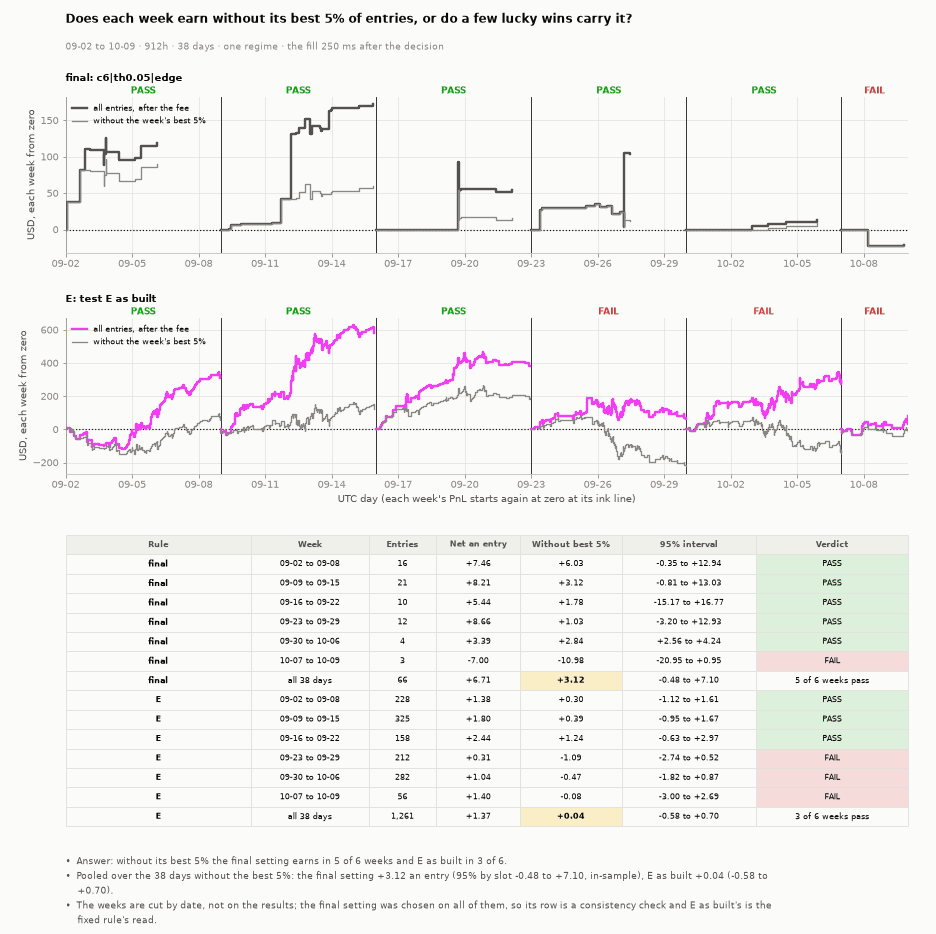

In [29]:
_r6 = {"cell": (f"final: {CFG['name']}", CELL_ALL), "E": ("E: test E as built", E_ALL)}
_wk = ST.weeks_of(len(DAYS), WEEK)
_np = {k_: sum(1 for i_ in _wk if ST.stats(ST.by_days(e_, i_)).get("n") and ST.stats(ST.by_days(e_, i_))["per_ex_top5"] > 0) for k_, (t_, e_) in _r6.items()}
_notes = [f"Answer: without its best 5% the final setting earns in {_np['cell']} of {len(_wk)} weeks and E as built in {_np['E']} of {len(_wk)}.",
          f"Pooled over the {len(DAYS)} days without the best 5%: the final setting {sgn(S_CELL['per_ex_top5'])} an entry (95% by slot {sgn(S_CELL['per_ex_top5_lo'])} to {sgn(S_CELL['per_ex_top5_hi'])}, "
          f"in-sample), E as built {sgn(S_E['per_ex_top5'])} ({sgn(S_E['per_ex_top5_lo'])} to {sgn(S_E['per_ex_top5_hi'])}).",
          "The weeks are cut by date, not on the results; the final setting was chosen on all of them, so its row is a consistency check and E as built's is the fixed rule's read."]
figstyle.show(ST.weekly_ex5_fig(_r6, DAYS, WEEK, WIN, _notes), "fig:s4-weekly-ex5", FIGURES)

### S4.2 · Latency

The net an entry, the total and the entries a later order loses, against the delay from the decision to the ladder the order meets: tables seated at 150,
250, 500 and 1,000 ms where every day is seated at that delay, and whole seconds added to the 250 ms table (1,250 to 5,250 ms). The study's 250 ms is an
assumption [U] until our own tick-to-trade is measured. The timing audit (2026-10-11, finding 1) showed the net an entry alone misleads here: with the limit at
the ask seen a later order loses exactly the entries whose book re-priced, which were the best ones, so the per-entry net of the survivors can hold while the
dollars fall.

In [30]:
_lat_df = pd.DataFrame([dict(rule=lab_, delay_ms=r_["ms"], how=r_["how"], n=r_["s"]["n"], per=r_["s"]["per"], lo=r_["s"]["per_lo"], hi=r_["s"]["per_hi"], ex5=r_["s"]["per_ex_top5"],
                             total_usd=r_["total"], fill_share=r_["fill_share"], lost_n=r_["lost_n"], lost_net_at_250=r_["lost_per"], kept_n=r_["kept_n"], kept_net_at_250=r_["kept_per"],
                             new_n=r_["new_n"], new_net=r_["new_per"]) for lab_, (t_, rows_) in LAT.items() for r_ in rows_])
display(HTML(_lat_df.round(3).to_html(index=False, border=0)))
print(f"seated tables {LAT_SEATED}; not seated on every day: {({k_: len(v_) for k_, v_ in LAT_MISSING.items()})}")

rule,delay_ms,how,n,per,lo,hi,ex5,total_usd,fill_share,lost_n,lost_net_at_250,kept_n,kept_net_at_250,new_n,new_net
E,150,seated table,1319,1.360,0.737,2.064,0.018,1794.264,1.046,0,NaN,0,NaN,0,NaN
E,250,seated table,1261,1.365,0.680,2.066,0.041,1721.580,1.000,0,NaN,1261,1.365,0,NaN
E,500,seated table,1192,1.120,0.398,1.814,-0.107,1335.429,0.945,0,NaN,0,NaN,0,NaN
E,1000,seated table,1137,1.093,0.370,1.813,-0.127,1242.948,0.902,0,NaN,0,NaN,0,NaN
E,1250,250 ms table + 1 s,1105,1.172,0.476,1.899,-0.070,1295.203,0.876,177,2.268,1084,1.218,21,4.637
E,2250,250 ms table + 2 s,1030,1.013,0.281,1.771,-0.224,1043.347,0.817,270,2.494,991,1.058,39,1.438
E,3250,250 ms table + 3 s,973,0.937,0.159,1.730,-0.407,911.719,0.772,337,2.373,924,0.998,49,1.978
E,5250,250 ms table + 5 s,932,0.866,0.005,1.688,-0.443,806.782,0.739,389,2.278,872,0.958,60,2.511
cell,150,seated table,69,6.773,2.065,11.031,3.227,467.361,1.045,0,NaN,0,NaN,0,NaN
cell,250,seated table,66,6.708,1.969,11.226,3.123,442.708,1.000,0,NaN,66,6.708,0,NaN


seated tables [150, 250, 500, 1000]; not seated on every day: {}


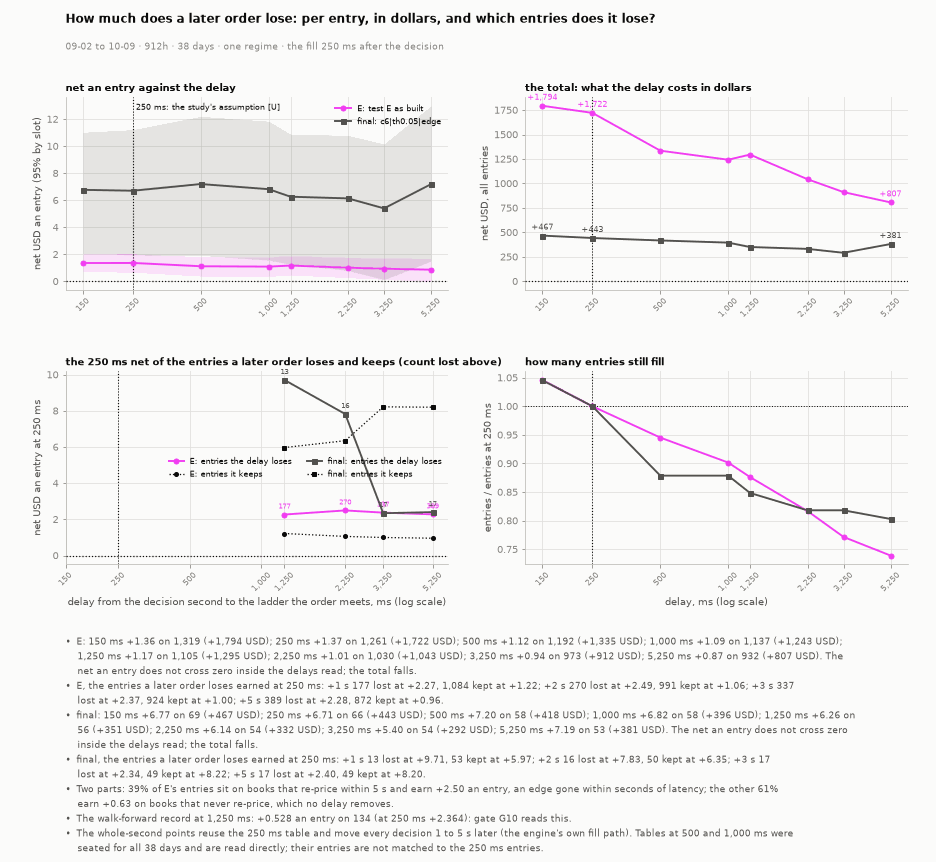

In [31]:
_notes = []
for lab_, (t_, rows_) in LAT.items():
    cx_ = ST.crossing(rows_)
    _notes.append(f"{t_.split(':')[0]}: " + "; ".join(f"{r_['ms']:,} ms {sgn(r_['s']['per'])} on {r_['s']['n']:,} ({sgn(r_['total'], 0)} USD)" for r_ in rows_) + ". "
                  + (f"The net an entry crosses zero near {cx_:,.0f} ms." if cx_ is not None else "The net an entry does not cross zero inside the delays read; the total falls."))
    sp_ = [r_ for r_ in rows_ if r_["kept_n"] and r_["ms"] != LAT_MS]
    if sp_:
        _notes.append(f"{t_.split(':')[0]}, the entries a later order loses earned at {LAT_MS} ms: " + "; ".join(f"+{(r_['ms'] - LAT_MS) // 1000} s {r_['lost_n']:,} lost at {sgn(r_['lost_per'])}, {r_['kept_n']:,} kept at {sgn(r_['kept_per'])}" for r_ in sp_) + ".")
_rp = REPRICE["E"]
_n_rest = _rp["same"][0] + _rp["lower"][0]
_notes.append(f"Two parts: {_rp['higher'][0] / max(S_E['n'], 1):.0%} of E's entries sit on books that re-price within 5 s and earn {sgn(_rp['higher'][1])} an entry, an edge gone within seconds of latency; "
              f"the other {_n_rest / max(S_E['n'], 1):.0%} earn {sgn((_rp['same'][2] + _rp['lower'][2]) / max(_n_rest, 1))} on books that never re-price, which no delay removes.")
_notes.append(f"The walk-forward record at 1,250 ms: {sgn(WF_1S['per'], 3)} an entry on {WF_1S['n']:,} (at 250 ms {sgn(TS['per'], 3)}): gate G10 reads this.")
_notes.append("The whole-second points reuse the 250 ms table and move every decision 1 to 5 s later (the engine's own fill path). "
              + (f"Tables at 500 and 1,000 ms were seated for all {len(DAYS)} days and are read directly; their entries are not matched to the 250 ms entries."
                 if not LAT_MISSING else f"Not seated on every day: {', '.join(f'{k_} ms ({len(v_)} days)' for k_, v_ in LAT_MISSING.items())}; those delays are left out, not interpolated."))
figstyle.show(ST.latency_fig(LAT, WIN, _notes, LAT_MS), "fig:s4-latency", FIGURES)

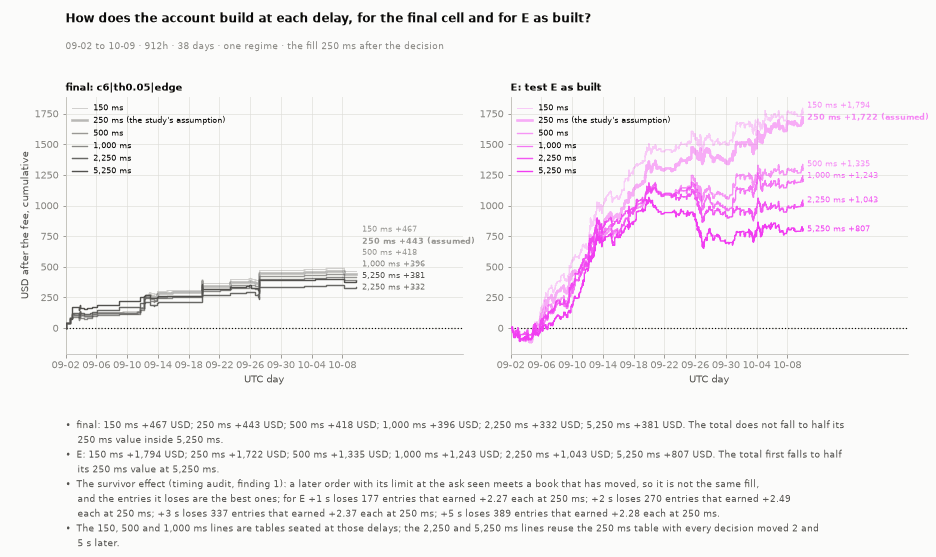

In [32]:
# ---- the same delays as paths over the days: the account after the fee at each delay, the final cell beside E as built ----
_show = (150, 250, 500, 1000, 2250, 5250)
_pan = {k_: (LAT[k_][0], [(f"{ms_:,} ms", DELAY_E[k_][ms_], ms_ == LAT_MS) for ms_ in _show if ms_ in DELAY_E[k_]]) for k_ in ("cell", "E")}
_notes = []
for k_ in ("cell", "E"):
    pts_ = [(ms_, float(np.sum(DELAY_E[k_][ms_]["net"])), ms_ == LAT_MS) for ms_ in DELAY_E[k_]]
    h_ = ST.halving(pts_)
    _notes.append(f"{LAT[k_][0].split(':')[0]}: " + "; ".join(f"{ms_:,} ms {sgn(v_, 0)} USD" for ms_, v_, b_ in pts_ if ms_ in _show) + ". "
                  + (f"The total first falls to half its {LAT_MS} ms value at {h_:,} ms." if h_ else f"The total does not fall to half its {LAT_MS} ms value inside {max(DELAY_E[k_]):,} ms."))
_sp = [r_ for r_ in LAT["E"][1] if r_["kept_n"] and r_["ms"] != LAT_MS]
_notes.append("The survivor effect (timing audit, finding 1): a later order with its limit at the ask seen meets a book that has moved, so it is not the same fill, and the "
              "entries it loses are the best ones; for E " + "; ".join(f"+{(r_['ms'] - LAT_MS) // 1000} s loses {r_['lost_n']:,} entries that earned {sgn(r_['lost_per'])} each at {LAT_MS} ms" for r_ in _sp) + ".")
_notes.append(f"The 150, 500 and 1,000 ms lines are tables seated at those delays; the 2,250 and 5,250 ms lines reuse the {LAT_MS} ms table with every decision moved 2 and 5 s later.")
figstyle.show(ST.paths_fig(_pan, DAYS, WIN, _notes, "How does the account build at each delay, for the final cell and for E as built?"), "fig:s4-delay-paths", FIGURES)

### S4.3 · Fees and slippage

Every net is after the taker fee (`rate x p x (1 - p)` a share, each market's own rate). Here the fee is shown, swept from none to three times the rate on the
same entries, and the limit is raised one and two cents over the cell's own limit.

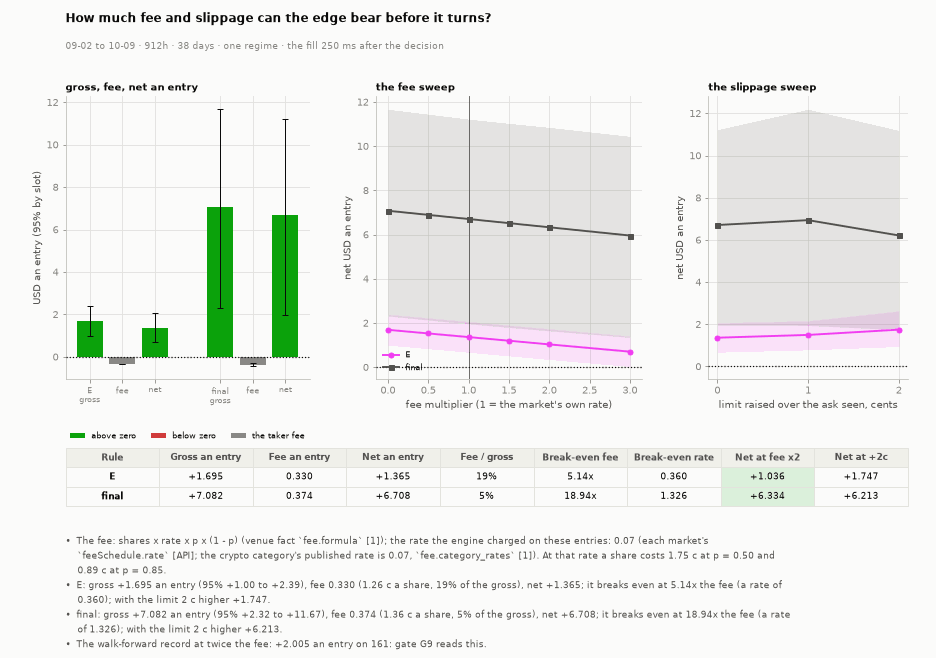

In [33]:
_c = COSTS["E"][1]
_rate = _c["rates"]
_notes = [f"The fee: shares x rate x p x (1 - p) (venue fact `fee.formula` [1]); the rate the engine charged on these entries: {', '.join(f'{r_:g}' for r_ in _rate)} (each market's `feeSchedule.rate` [API]; the crypto category's published rate is 0.07, `fee.category_rates` [1]). "
          + (f"At that rate a share costs {_rate[0] * 0.25 * 100:.2f} c at p = 0.50 and {_rate[0] * 0.85 * 0.15 * 100:.2f} c at p = 0.85." if len(_rate) == 1 else "")]
for lab_, (t_, c_) in COSTS.items():
    _notes.append(f"{t_.split(':')[0]}: gross {sgn(c_['gross'], 3)} an entry (95% {sgn(c_['gross_lo'])} to {sgn(c_['gross_hi'])}), fee {c_['fee_per']:.3f} ({c_['fee_per'] / c_['shares'] * 100:.2f} c a share, "
                  f"{c_['fee_per'] / c_['gross'] * 100 if c_['gross'] > 0 else float('nan'):.0f}% of the gross), net {sgn(c_['net'], 3)}; it breaks even at {c_['be_mult']:.2f}x the fee"
                  + (f" (a rate of {c_['be_mult'] * c_['rates'][0]:.3f})" if len(c_["rates"]) == 1 else "") + f"; with the limit 2 c higher {sgn(dict(c_['slip'])[0.02]['per'], 3)}.")
_notes.append(f"The walk-forward record at twice the fee: {sgn(WF_FEE2['per'], 3)} an entry on {WF_FEE2['n']:,}: gate G9 reads this.")
figstyle.show(ST.cost_fig(COSTS, WIN, _notes), "fig:s4-costs", FIGURES)

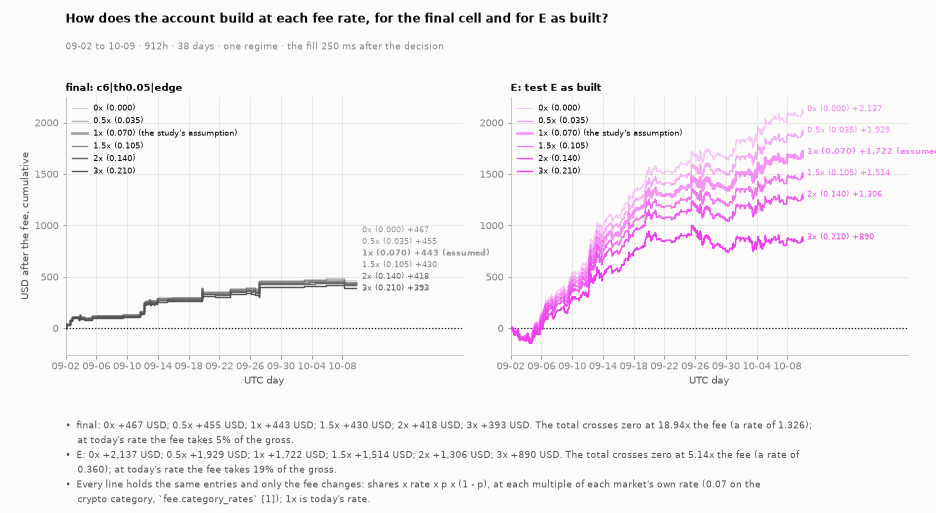

In [34]:
# ---- the same fee sweep as paths over the days: the account after the fee at each multiple of the rate, the final cell beside E as built ----
FEE_E = {k_: ST.fee_entries(CAND, TAB, cfg_, FEE_MULTS) for k_, cfg_ in (("cell", CFG), ("E", CFG_E))}
_r0 = float(COSTS["E"][1]["rates"][0]) if len(COSTS["E"][1]["rates"]) == 1 else 0.07
_pan = {k_: (COSTS[k_][0], [(f"{m_:g}x ({m_ * _r0:.3f})", FEE_E[k_][m_], m_ == 1.0) for m_ in FEE_MULTS]) for k_ in ("cell", "E")}
_notes = []
for k_ in ("cell", "E"):
    c_ = COSTS[k_][1]
    _notes.append(f"{COSTS[k_][0].split(':')[0]}: " + "; ".join(f"{m_:g}x {sgn(float(np.sum(FEE_E[k_][m_]['net'])), 0)} USD" for m_ in FEE_MULTS)
                  + f". The total crosses zero at {c_['be_mult']:.2f}x the fee (a rate of {c_['be_mult'] * _r0:.3f})"
                  + (f"; at today's rate the fee takes {c_['fee_per'] / c_['gross']:.0%} of the gross." if c_["gross"] > 0 else "; the gross is not positive."))
_notes.append(f"Every line holds the same entries and only the fee changes: shares x rate x p x (1 - p), at each multiple of each market's own rate ({_r0:g} on the crypto category, `fee.category_rates` [1]); 1x is today's rate.")
figstyle.show(ST.paths_fig(_pan, DAYS, WIN, _notes, "How does the account build at each fee rate, for the final cell and for E as built?"), "fig:s4-fee-paths", FIGURES)

### S4.4 · Slices

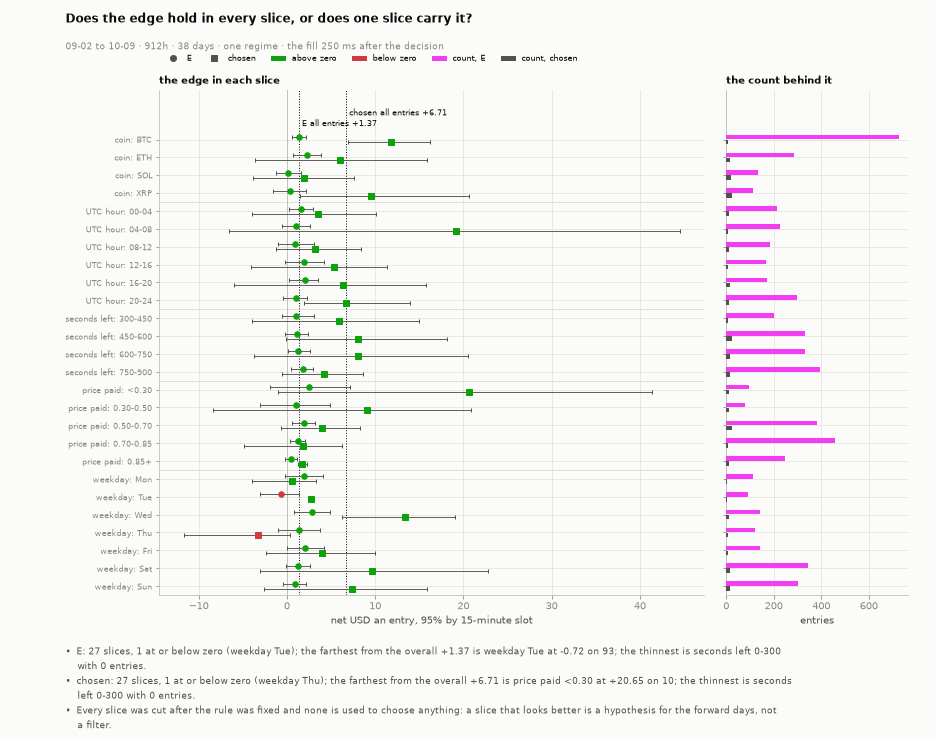

In [35]:
SL = {"E": ("E: test E as built", ST.slices(E_ALL, TAB, DAYS)), "cell": (f"chosen: {CFG['name']}", ST.slices(CELL_ALL, TAB, DAYS))}
_ov = {"E": S_E["per"], "cell": S_CELL["per"]}
_notes = []
for lab_, (t_, rows_) in SL.items():
    neg_ = [f"{d_} {l_}" for d_, l_, v_, lo_, hi_, n_ in rows_ if v_ <= 0]
    thin_ = min(rows_, key=lambda r_: r_[5])
    far_ = max(rows_, key=lambda r_: abs(r_[2] - _ov[lab_]) if np.isfinite(r_[2]) else -1)
    _notes.append(f"{t_.split(':')[0]}: {len(rows_)} slices, {len(neg_)} at or below zero" + (f" ({', '.join(neg_)})" if neg_ else "") + f"; the farthest from the overall {_ov[lab_]:+.2f} is {far_[0]} {far_[1]} at {far_[2]:+.2f} on {far_[5]:,}; the thinnest is {thin_[0]} {thin_[1]} with {thin_[5]:,} entries.")
_notes.append("Every slice was cut after the rule was fixed and none is used to choose anything: a slice that looks better is a hypothesis for the forward days, not a filter.")
figstyle.show(ST.slices_fig(SL, _ov, WIN, _notes), "fig:s4-slices", FIGURES)

### S4.5 · Steadiness over weeks

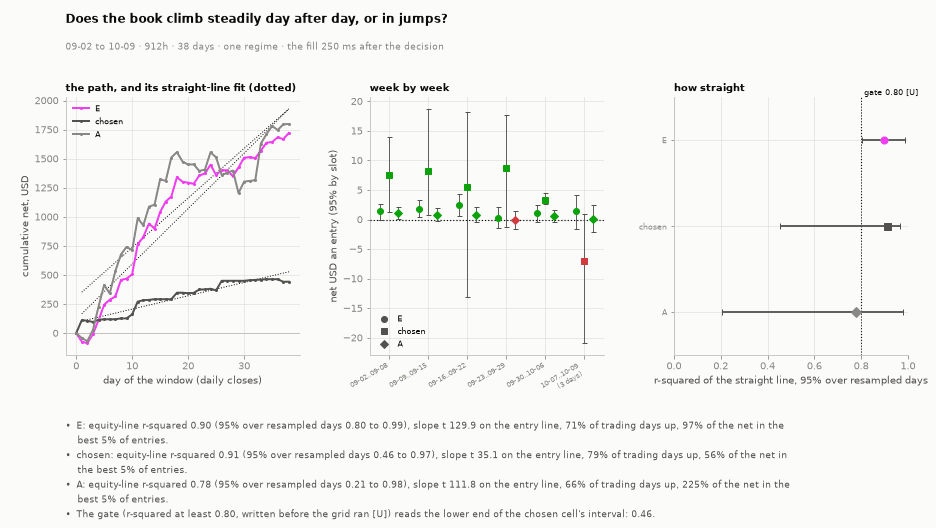

In [36]:
STEADY = {k_: (t_, e_) for k_, t_, e_ in (("E", "E: test E as built", E_ALL), ("cell", f"chosen: {CFG['name']}", CELL_ALL), ("A", "A: rule A", A_ALL))}
_nd = len(DAYS)
R2 = {k_: (ST.r2_line(ST.daily(e_, _nd)), *ST.r2_ci(ST.daily(e_, _nd))) for k_, (t_, e_) in STEADY.items()}
_notes = []
for k_, (t_, e_) in STEADY.items():
    s_ = B.summarize(e_, TAB, k_) if len(e_["net"]) else dict(n=0)
    _notes.append(f"{t_.split(':')[0]}: equity-line r-squared {R2[k_][0]:.2f} (95% over resampled days {R2[k_][1]:.2f} to {R2[k_][2]:.2f}), slope t {s_.get('eq_slope_t', float('nan')):.1f} on the entry line, "
                  f"{s_.get('days_pos', float('nan')):.0%} of trading days up, " + (f"{s_['top5_share'] * 100:.0f}% of the net in the best 5% of entries." if np.isfinite(s_.get('top5_share', float('nan'))) else "a net at or below zero, so no share in the best 5%."))
_notes.append(f"The gate (r-squared at least {R2_MIN:.2f}, written before the grid ran [U]) reads the lower end of the chosen cell's interval: {R2['cell'][1]:.2f}.")
figstyle.show(ST.steady_fig(STEADY, DAYS, R2_MIN, WIN, _notes), "fig:s4-steady", FIGURES)

### S4.6 · Exits

One figure, no exit search: holding to expiry against a sale at the near bid after 60, 120 and 300 seconds and a take-profit at 0.95, on the same entries.

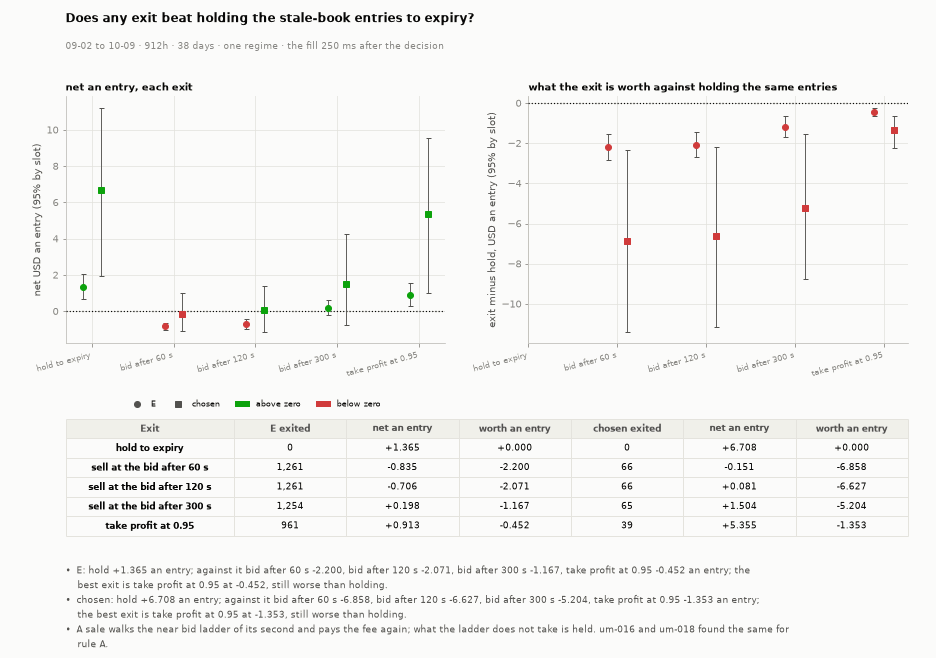

In [37]:
EXITS = {"E": ("E: test E as built", ST.exit_variants(TAB, E_ALL)), "cell": (f"chosen: {CFG['name']}", ST.exit_variants(TAB, CELL_ALL))}
_notes = []
for lab_, (t_, v_) in EXITS.items():
    base_ = v_["hold to expiry"]
    w_ = {nm_: float(np.mean(np.asarray(x_["net"]) - np.asarray(base_["net"]))) for nm_, x_ in v_.items() if nm_ != "hold to expiry"}
    best_ = max(w_, key=w_.get)
    _notes.append(f"{t_.split(':')[0]}: hold {sgn(ST.stats(base_)['per'], 3)} an entry; against it " + ", ".join(f"{nm_.replace('sell at the bid after', 'bid after')} {v2_:+.3f}" for nm_, v2_ in w_.items())
                  + f" an entry; the best exit is {best_} at {w_[best_]:+.3f}" + (" and it beats holding." if w_[best_] > 0 else ", still worse than holding."))
_notes.append("A sale walks the near bid ladder of its second and pays the fee again; what the ladder does not take is held. um-016 and um-018 found the same for rule A.")
figstyle.show(ST.exits_fig(EXITS, WIN, _notes), "fig:s4-exits", FIGURES)

## S5 · Risk and diagnostics

The daily record of the chosen cell and of E on every seated day, the drawdown against the limit written before the grid ran, the concentration of the net,
and the stop against the realised path.

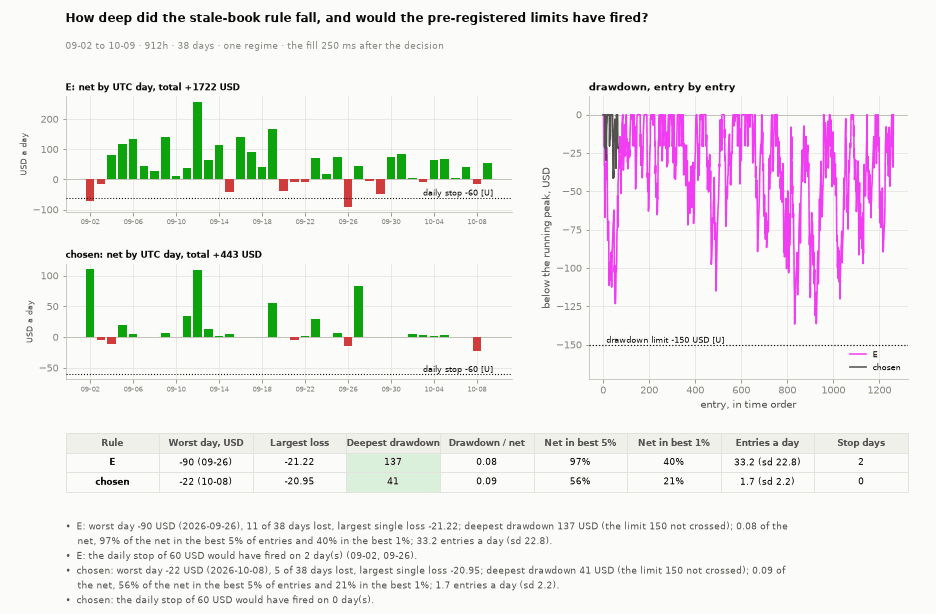

In [38]:
RISK = {"E": ("E: test E as built", ST.risk_read(E_ALL, len(DAYS), BOOK_USD, STOP_DAY_USD, DD_LIMIT_USD)), "cell": (f"chosen: {CFG['name']}", ST.risk_read(CELL_ALL, len(DAYS), BOOK_USD, STOP_DAY_USD, DD_LIMIT_USD))}
_notes = []
for lab_, (t_, r_) in RISK.items():
    _notes.append(f"{t_.split(':')[0]}: worst day {r_['worst_day']:+.0f} USD ({DAYS[r_['worst_idx']]}), {r_['days_lost']} of {len(DAYS)} days lost, largest single loss {r_['largest_loss']:+.2f}; "
                  f"deepest drawdown {r_['max_dd']:.0f} USD (the limit {DD_LIMIT_USD:.0f} {'crossed' if r_['dd_crossed'] else 'not crossed'}); "
                  + (f"{r_['dd_over_net']:.2f} of the net, {r_['top5'] * 100:.0f}% of the net in the best 5% of entries and {r_['top1'] * 100:.0f}% in the best 1%; " if r_["net"] > 0 else "the net is at or below zero; ")
                  + f"{r_['per_day']:.1f} entries a day (sd {r_['per_day_sd']:.1f}).")
    _notes.append(f"{t_.split(':')[0]}: the daily stop of {STOP_DAY_USD:.0f} USD would have fired on {len(r_['stop_days'])} day(s)" + (f" ({', '.join(DAYS[i_][5:] for i_ in r_['stop_days'])})." if r_["stop_days"] else "."))
figstyle.show(ST.risk_fig(RISK, DAYS, STOP_DAY_USD, DD_LIMIT_USD, WIN, _notes), "fig:s5-risk", FIGURES)

## S6 · Decision

Capacity under both fill limits (`tf15_capacity`: the walk up the ladder to our edge price and the re-run at each clip; the ask-seen form re-run the same way),
then the gates. A size prints only when every gate of S2 to S5 has passed (`SIZED`); otherwise the rungs print as information only.

In [39]:
import tf15_capacity as CAP
_t = time.time()
CAP_MASKS = {"gates": {"E": CAND.gates(TAB, CFG_E), "cell": CAND.gates(TAB, CFG)}}
CAP_EST = {"E": CAP.estimate(TAB, E_ALL, CAP_MASKS, "E", len(DAYS), t_min=CFG_E["t_min"], theta=CFG_E["theta"]),
           "cell": CAP.estimate(TAB, CELL_ALL, CAP_MASKS, "cell", len(DAYS), t_min=CFG["t_min"], theta=CFG["theta"])}
CURVES = {}
for lab_, cfg_, t_ in (("E", CFG_E, "E: test E as built"), ("cell", CFG, f"chosen: {CFG['name']}")):
    CURVES[(lab_, "ask")] = (t_, ST.curve_ask(TAB, CAP_MASKS, lab_, len(DAYS), cfg_["t_min"], CAP.CLIPS))
    CURVES[(lab_, "edge")] = (t_, CAP.rerun_curve(TAB, CAP_MASKS, lab_, len(DAYS), cfg_["t_min"], CAP.CLIPS, theta=cfg_["theta"]))
_cap = pd.DataFrame([dict(rule=lab_, limit=f_, clip=r_["clip"], n=r_["n"], per_day=r_["per_day"], per=r_["per"], lo=r_["lo"], hi=r_["hi"], ex5=r_["ex5"], full=r_["full"], day_net=r_["day_net"])
                     for (lab_, f_), (t_, rows_) in CURVES.items() for r_ in rows_])
display(Markdown(f"**The clip curve per fill limit** ({len(DAYS)} days; full: the share of entries that got the whole clip; computed in {time.time() - _t:.0f}s)"))
display(HTML(_cap.round(3).to_html(index=False, border=0)))
SURV = {k_: max([r_["clip"] for r_ in rows_ if np.isfinite(r_["ex5"]) and r_["ex5"] > 0], default=0.0) for k_, (t_, rows_) in CURVES.items()}

**The clip curve per fill limit** (38 days; full: the share of entries that got the whole clip; computed in 8s)

rule,limit,clip,n,per_day,per,lo,hi,ex5,full,day_net
E,ask,20.0,1261,33.184,1.365,0.680,2.066,0.041,0.722,45.305
E,ask,50.0,1261,33.184,2.604,1.209,4.109,0.007,0.573,86.425
E,ask,100.0,1261,33.184,4.054,1.693,6.587,-0.297,0.441,134.538
E,ask,200.0,1261,33.184,6.009,2.272,9.961,-0.945,0.288,199.394
E,ask,500.0,1261,33.184,8.328,1.541,15.277,-4.346,0.123,276.358
E,edge,20.0,1447,38.079,1.950,1.093,2.910,-0.080,0.806,74.256
E,edge,50.0,1447,38.079,3.785,2.086,5.488,0.034,0.695,144.122
E,edge,100.0,1447,38.079,6.374,3.573,9.195,0.488,0.612,242.733
E,edge,200.0,1447,38.079,9.999,5.280,14.797,0.802,0.527,380.757
E,edge,500.0,1447,38.079,16.421,6.519,26.114,-1.431,0.368,625.307


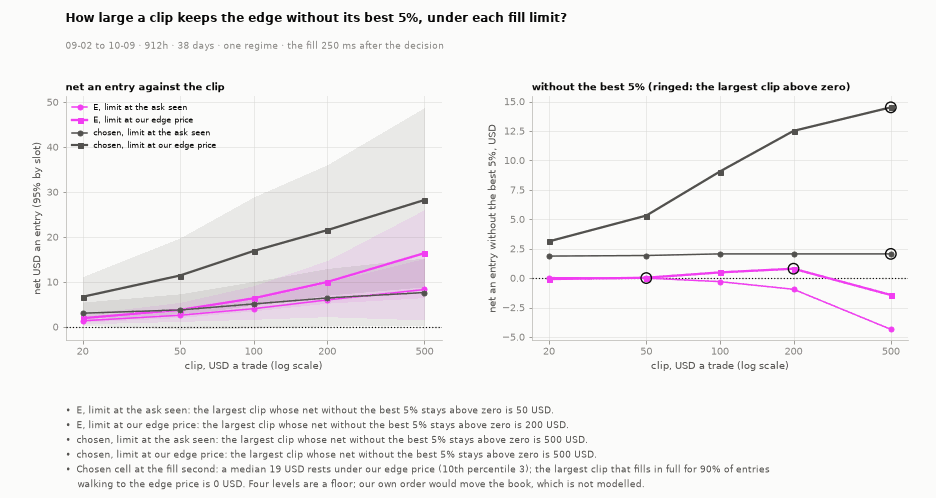

In [40]:
_notes = [f"{CURVES[k_][0].split(':')[0]}, limit at {'the ask seen' if k_[1] == 'ask' else 'our edge price'}: the largest clip whose net without the best 5% stays above zero is "
          + (f"{SURV[k_]:g} USD." if SURV[k_] else "none: no clip read keeps it above zero.") for k_ in CURVES]
_e = CAP_EST["cell"]["row"]
_notes.append(f"Chosen cell at the fill second: a median {_e['usd_edge_med']:,.0f} USD rests under our edge price (10th percentile {_e['usd_edge_p10']:,.0f}); "
              f"the largest clip that fills in full for 90% of entries walking to the edge price is {_e['full_clip']:g} USD. Four levels are a floor; our own order would move the book, which is not modelled.")
figstyle.show(ST.clip_fig(CURVES, WIN, _notes), "fig:s6-clip", FIGURES)

In [41]:
# ---- the gates, as data, then the decision ----
def gate(i, sec, label, name, reading, verdict, would):
    GATES.append({"id": i, "section": sec, "label": label, "name": name, "reading": reading, "verdict": verdict if isinstance(verdict, str) else ("PASS" if verdict else "FAIL"), "would_change": would})
PF_ = lambda ok_: "PASS" if ok_ else "FAIL"
gate("G3", "S3", "Tuned beats E OOS", f"Does tuning beat the rule as built out of sample? Over the {len(OOS_DAYS)} traded days ({OOS_DAYS[0][5:]} to {OOS_DAYS[-1][5:]}), each week traded with the setting "
     "chosen on the weeks before it, E tuned's net an entry without the best 5% must be above E as built's (3 s) on the same days, and its 95% interval's low end above zero",
     f"E tuned {sgn(TS['per_ex_top5'], 3)} ({sgn(TS['per_ex_top5_lo'])} to {sgn(TS['per_ex_top5_hi'])}) against E as built {sgn(TS_E['per_ex_top5'], 3)}", G_WALK,
     "E as built ahead, or the interval reaching zero")
gate("G4", "S3", f"Same window {STABLE_MIN} of {len(NS_CHOSEN)} weeks", f"Is the pick the same week after week? The {len(NS_CHOSEN)} weekly picks, each made only on the weeks before its traded week, "
     f"must choose the same stale window at least {STABLE_MIN} times",
     f"chosen n {', '.join(str(n_) for n_ in NS_CHOSEN)} s; " + (f"{N_MODE} s in {N_MODE_COUNT} folds" if N_MODE_COUNT > 1 else "no window twice"), G_STABLE, "a choice that jumps")
gate("G5", "S3", "OOS net above zero", "E tuned's walk-forward net an entry is above zero", f"{sgn(TS['per'], 3)} USD an entry (95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}) on {TS['n']:,}",
     bool(TS.get("n")) and TS["per"] > 0, "a net at or below zero")
gate("G6", "S3", "OOS ex-5% above zero", "E tuned's walk-forward net an entry stays above zero without its best 5% of entries", f"{sgn(TS['per_ex_top5'], 3)} USD an entry",
     bool(TS.get("n")) and TS["per_ex_top5"] > 0, "a few wins carrying the record")
gate("G7", "S4", "Beats random burst", f"E tuned's walk-forward record beats the same count of entries per day and coin at its weeks' seconds that pass every condition of each week's cell but the burst, one-sided p below {P_GATE:.2f}",
     f"p {P_REC_BURST:.4f} on {N_DRAWS:,} draws (null median {sgn(float(np.nanmedian(REC_BURST['per'])), 3)}, the record {sgn(TS['per'], 3)})", bool(np.isfinite(P_REC_BURST) and P_REC_BURST < P_GATE),
     f"a p of {P_GATE:.2f} or more")
_b = OOS2W_CELL[1:]
gate("G8", "S4", "Both OOS blocks pass", "both out-of-sample blocks of the final cell pass (at least 20 entries, above zero, inside the in-sample forecast); a consistency check, since it was chosen on every day",
     "; ".join(f"{b_['name']} {sgn(b_['s'].get('per', float('nan')), 3)} {b_['verdict']}" for b_ in _b), len(_b) >= 2 and all(b_["verdict"] == "PASS" for b_ in _b), "a block below zero or outside the forecast")
gate("G9", "S4", "Survives fee x2", "E tuned's walk-forward net an entry stays above zero at twice the fee", f"{sgn(WF_FEE2['per'], 3)} USD an entry", bool(WF_FEE2.get("n")) and WF_FEE2["per"] > 0,
     "an edge smaller than a fee")
gate("G10", "S4", "1 s delay keeps sign", "E tuned's walk-forward net an entry stays above zero with the order one second later (1,250 ms)", f"{sgn(WF_1S['per'], 3)} at 1,250 ms against {sgn(TS['per'], 3)} at 250 ms",
     bool(WF_1S.get("n")) and WF_1S["per"] > 0, "an edge that lives inside one second")
_dsr = DSR["dsr"] if DSR and np.isfinite(DSR["dsr"]) else float("nan")
gate("G11", "S4", "Deflated Sharpe", f"the walk-forward record's Sharpe an entry deflated over the {N_REGISTERED} registered cells is at least {DSR_MIN:.2f}", f"{_dsr:.2f}", bool(np.isfinite(_dsr) and _dsr >= DSR_MIN), "luck of the best of N")
gate("G12", "S4", "Climbs steadily", f"the lower end of the final cell's equity-line r-squared (95% over resampled days) is at least {R2_MIN:.2f} [U]", f"{R2['cell'][0]:.2f} ({R2['cell'][1]:.2f} to {R2['cell'][2]:.2f})",
     R2["cell"][1] >= R2_MIN, "a path carried by a few days")
gate("G13", "S3", "Plateau holds", "the final cell and its neighbours one step in window and discount to fair value are above zero without the best 5% on every seated day", f"{'every' if PLATEAU_OK else 'not every'} cell of the block above zero",
     PLATEAU_OK, "a spike in the grid")
gate("G14", "S5", "Drawdown inside limit", f"the final cell's deepest drawdown over every seated day stays under the pre-registered {DD_LIMIT_USD:.0f} USD [U]", f"{RISK['cell'][1]['max_dd']:.0f} USD",
     not RISK["cell"][1]["dd_crossed"], "a deeper drawdown")
gate("G15", "S3", f"Weeks agree {STABLE_MIN} of {len(WF['folds'])}", f"Does the week a pick is traded on agree with the weeks it was chosen from? At least {STABLE_MIN} of the "
     f"{len(WF['folds'])} traded weeks must net above zero without the best 5% and inside the pick's 95% interval on its choosing weeks",
     "; ".join(f"{WK(f_)} {'agrees' if f_['agree'] else 'collapses'}" for f_ in WF["folds"]), G_AGREE, "choosing weeks that fool us")
CORE = [g_["id"] for g_ in GATES]
GV_ = {g_["id"]: g_["verdict"] for g_ in GATES}
SIZED = all(GV_[i_] == "PASS" for i_ in CORE)
WORD = "1x" if SIZED else "NO SIZE"
CLASS = "A" if SIZED else ("B" if TS.get("n", 0) and TS["per"] > 0 else "C")
GATES.append({"id": "G16", "section": "S6", "label": "Sized only if passed", "name": "a size only when every gate G1 to G15 passed; else the rungs are information only",
              "reading": f"{'SIZED' if SIZED else 'NO SIZE'}: {', '.join(g_['label'] for g_ in GATES if g_['verdict'] != 'PASS') or 'none failed'}", "verdict": "PASS" if SIZED else "FAIL", "would_change": "any gate it reads"})
_rungs = [(lab_, f_, r_) for (lab_, f_), (t_, rows_) in CURVES.items() if lab_ == "cell" for r_ in rows_]
display(Markdown(f"**Decision: {'a USD ' + format(CLIP_USD, 'g') + ' clip, one entry a window, paper only' if SIZED else 'NO SIZE, information only'}.** "
                 + ("Every gate passed." if SIZED else f"Not passed: {', '.join(g_['label'] for g_ in GATES if g_['verdict'] != 'PASS' and g_['id'] in CORE)}.")
                 + " The rungs of the final cell" + (":" if SIZED else " (information only):")))
display(HTML(pd.DataFrame([dict(limit=f_, clip=r_["clip"], entries_a_day=r_["per_day"], net_per_entry=r_["per"], net_ex_best5=r_["ex5"], net_a_day=r_["day_net"]) for lab_, f_, r_ in _rungs]).round(3).to_html(index=False, border=0)))

**Decision: NO SIZE, information only.** Not passed: Tuned beats E OOS, Same window 4 of 5 weeks, OOS ex-5% above zero, Beats random burst, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Weeks agree 4 of 5. The rungs of the final cell (information only):

limit,clip,entries_a_day,net_per_entry,net_ex_best5,net_a_day
ask,20.0,1.447,3.059,1.873,4.427
ask,50.0,1.447,3.778,1.923,5.468
ask,100.0,1.447,5.113,2.061,7.400
ask,200.0,1.447,6.445,2.061,9.328
ask,500.0,1.447,7.657,2.061,11.083
edge,20.0,1.737,6.708,3.123,11.650
edge,50.0,1.737,11.432,5.313,19.855
edge,100.0,1.737,16.892,9.057,29.339
edge,200.0,1.737,21.523,12.507,37.382
edge,500.0,1.737,28.238,14.507,49.044


## S7 · Verdict

In [42]:
WORD_V = "MONEY" if SIZED else f"class {CLASS}"
_failed = [g_["label"] for g_ in GATES if g_["verdict"] != "PASS" and g_["id"] in CORE]
_why = [f"E tuned, each week chosen on the weeks before it, earned {sgn(TS['per'], 3)} USD an entry on {TS['n']:,} entries over {len(OOS_DAYS)} days (95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}), "
        f"{sgn(TS['per_ex_top5'], 3)} without the best 5% ({sgn(TS['per_ex_top5_lo'])} to {sgn(TS['per_ex_top5_hi'])}); E as built on the same days {sgn(TS_E['per'], 3)}, {sgn(TS_E['per_ex_top5'], 3)} without the best 5%",
        f"the weekly picks chose the stale window {', '.join(str(n_) for n_ in NS_CHOSEN)} s and {N_AGREE} of {len(WF['folds'])} traded weeks agreed with their choosing weeks; the final cell {CFG['name']}" + (" is E as built" if FINAL_IS_E else "") + f"; deflated Sharpe {_dsr:.2f} over {N_REGISTERED} cells; random burst p {P_REC_BURST:.4f}",
        f"E tuned at 1,250 ms {sgn(WF_1S['per'], 3)}, at twice the fee {sgn(WF_FEE2['per'], 3)}; not passed: {', '.join(_failed) or 'none'}"]
NEXT_BET = (f"the forward read of {CFG['name']} frozen as it stands, on the days from 10-10 as they seat, registered first, on the engine with the frozen-feed mask and the gate read at our own latency "
            "(the timing audit), a generator stub ...-stale-book-forward.build.py not built here" + ("" if FINAL_IS_E else "; beside it test E as built"))
VERDICT_MD = (f"**The answer: {WORD_V}.** " + ("Every gate passed." if SIZED else ("Real in sign out of sample, not sizeable. " if CLASS == "B" else "No money out of sample. "))
              + "\n\n" + "\n".join(f"- {w_[0].upper() + w_[1:]}." for w_ in _why) + f"\n\n**Next bet.** {NEXT_BET[0].upper() + NEXT_BET[1:]}."
              + f"\n\n**Engine caveats.** The gate reads the book at the Binance print, and {OLD_E[0]} of E's entries ({sgn(OLD_E[2], 0)} USD) sit on a book row 2 s old or more"
              + (f", {SILENT_E[0]} of them ({sgn(SILENT_E[1], 0)} USD) with every book of the slot silent" if FEED_LIVE is not None else "")
              + "; both stay in this run (timing audit, findings 2 and 3). The engine with the feed mask and the gate read 100 ms late had not landed in full when this ran: a re-run on it is due.")
display(Markdown(VERDICT_MD))
for g_ in GATES:
    assert g_["verdict"] in REPORT.GATE_VERDICTS, g_
    assert len(g_["label"]) <= REPORT.MAX_GATE_LABEL, (g_["label"], len(g_["label"]))
assert len({g_["id"] for g_ in GATES}) == len(GATES)
GATES.sort(key=lambda g_: int(g_["id"][1:]))
GV = {g_["id"]: g_["verdict"] for g_ in GATES}
display(Markdown("**Gates**\n\n| Id | Section | Gate | Reading | Verdict |\n|---|---|---|---|---|\n" + "\n".join(f"| {g_['id']} | {g_['section']} | {g_['label']} | {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))
RESULT_LINES = [f"RESULT {RUN_ID} final_cell={CFG['name']}", f"RESULT {RUN_ID} wf_chosen_n={'/'.join(str(n_) for n_ in NS_CHOSEN)}", f"RESULT {RUN_ID} wf_weeks_agree={N_AGREE}", f"RESULT {RUN_ID} wf_entries={TS['n']}",
                f"RESULT {RUN_ID} wf_net_per_entry_usd={TS['per']:.4f}", f"RESULT {RUN_ID} wf_net_ex_best5_usd={TS['per_ex_top5']:.4f}", f"RESULT {RUN_ID} wf_net_ex_best5_lo_usd={TS['per_ex_top5_lo']:.4f}",
                f"RESULT {RUN_ID} E_wf_net_ex_best5_usd={TS_E['per_ex_top5']:.4f}", f"RESULT {RUN_ID} E_wf_net_per_entry_usd={TS_E['per']:.4f}", f"RESULT {RUN_ID} deflated_sharpe={_dsr:.3f}",
                f"RESULT {RUN_ID} wf_p_random_burst={P_REC_BURST:.4f}", f"RESULT {RUN_ID} wf_delay1s_minus_base_usd={WF_1S['per'] - TS['per']:.4f}", f"RESULT {RUN_ID} wf_win_rate_pct={TS['win'] * 100:.2f}", f"RESULT {RUN_ID} wf_net_pnl_usd={TS['net']:.2f}",
                f"RESULT {RUN_ID} E_net_per_entry_usd={S_E['per']:.4f}", f"RESULT {RUN_ID} n_cells={N_REGISTERED}"]
print("\n".join(RESULT_LINES))

**The answer: class B.** Real in sign out of sample, not sizeable. 

- E tuned, each week chosen on the weeks before it, earned +2.364 USD an entry on 161 entries over 31 days (95% -0.65 to +5.75), -0.394 without the best 5% (-2.38 to +2.02); E as built on the same days +1.361, -0.016 without the best 5%.
- The weekly picks chose the stale window 1, 3, 10, 12, 6 s and 3 of 5 traded weeks agreed with their choosing weeks; the final cell c6|th0.05|edge; deflated Sharpe 0.00 over 162 cells; random burst p 0.2577.
- E tuned at 1,250 ms +0.528, at twice the fee +2.005; not passed: Tuned beats E OOS, Same window 4 of 5 weeks, OOS ex-5% above zero, Beats random burst, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Weeks agree 4 of 5.

**Next bet.** The forward read of c6|th0.05|edge frozen as it stands, on the days from 10-10 as they seat, registered first, on the engine with the frozen-feed mask and the gate read at our own latency (the timing audit), a generator stub ...-stale-book-forward.build.py not built here; beside it test E as built.

**Engine caveats.** The gate reads the book at the Binance print, and 18 of E's entries (+92 USD) sit on a book row 2 s old or more, 14 of them (+67 USD) with every book of the slot silent; both stay in this run (timing audit, findings 2 and 3). The engine with the feed mask and the gate read 100 ms late had not landed in full when this ran: a re-run on it is due.

**Gates**

| Id | Section | Gate | Reading | Verdict |
|---|---|---|---|---|
| G1 | S2 | Windows have a book | 94.2% of 14,592 windows | **PASS** |
| G2 | S2 | Live replay agrees | 1,261 entries, only-vectorised 0, only-live 0; planted differs: True | **PASS** |
| G3 | S3 | Tuned beats E OOS | E tuned -0.394 (-2.38 to +2.02) against E as built -0.016 | **FAIL** |
| G4 | S3 | Same window 4 of 5 weeks | chosen n 1, 3, 10, 12, 6 s; no window twice | **FAIL** |
| G5 | S3 | OOS net above zero | +2.364 USD an entry (95% -0.65 to +5.75) on 161 | **PASS** |
| G6 | S3 | OOS ex-5% above zero | -0.394 USD an entry | **FAIL** |
| G7 | S4 | Beats random burst | p 0.2577 on 1,000 draws (null median +1.805, the record +2.364) | **FAIL** |
| G8 | S4 | Both OOS blocks pass | out-of-sample +7.197 PASS; out-of-sample 2 -1.066 thin | **FAIL** |
| G9 | S4 | Survives fee x2 | +2.005 USD an entry | **PASS** |
| G10 | S4 | 1 s delay keeps sign | +0.528 at 1,250 ms against +2.364 at 250 ms | **PASS** |
| G11 | S4 | Deflated Sharpe | 0.00 | **FAIL** |
| G12 | S4 | Climbs steadily | 0.91 (0.46 to 0.97) | **FAIL** |
| G13 | S3 | Plateau holds | every cell of the block above zero | **PASS** |
| G14 | S5 | Drawdown inside limit | 41 USD | **PASS** |
| G15 | S3 | Weeks agree 4 of 5 | 09-09 to 09-15 collapses; 09-16 to 09-22 agrees; 09-23 to 09-29 agrees; 09-30 to 10-06 agrees; 10-07 to 10-09 collapses | **FAIL** |
| G16 | S6 | Sized only if passed | NO SIZE: Tuned beats E OOS, Same window 4 of 5 weeks, OOS ex-5% above zero, Beats random burst, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Weeks agree 4 of 5 | **FAIL** |

RESULT um-023 final_cell=c6|th0.05|edge
RESULT um-023 wf_chosen_n=1/3/10/12/6
RESULT um-023 wf_weeks_agree=3
RESULT um-023 wf_entries=161
RESULT um-023 wf_net_per_entry_usd=2.3637
RESULT um-023 wf_net_ex_best5_usd=-0.3942
RESULT um-023 wf_net_ex_best5_lo_usd=-2.3768
RESULT um-023 E_wf_net_ex_best5_usd=-0.0163
RESULT um-023 E_wf_net_per_entry_usd=1.3612
RESULT um-023 deflated_sharpe=0.004
RESULT um-023 wf_p_random_burst=0.2577
RESULT um-023 wf_delay1s_minus_base_usd=-1.8359
RESULT um-023 wf_win_rate_pct=72.67
RESULT um-023 wf_net_pnl_usd=380.55
RESULT um-023 E_net_per_entry_usd=1.3652
RESULT um-023 n_cells=162


In [43]:
# ---- the card ----
_cut = lambda s, n: s if len(s) <= n else s[: n - 1].rstrip() + "."
mk = lambda metric, value, bar="", verdict="", gate=None: {"metric": metric, "value": value, "bar": bar, "verdict": GV[gate] if gate else verdict, **({"gate": gate} if gate else {})}
_ts_slots = np.unique(TAB.slot[np.isin(TAB.day, OOS_IDX)])
_sl = np.bincount(np.searchsorted(_ts_slots, ENT["slot"]), weights=ENT["net"], minlength=len(_ts_slots)) if TS.get("n") else np.zeros(1)
SLOT_SH = float(_sl.mean() / _sl.std(ddof=1) * np.sqrt(B.SLOTS_PER_DAY * 365)) if TS.get("n") and _sl.std(ddof=1) > 0 else float("nan")
_wins, _loss = ENT["net"][ENT["net"] > 0], ENT["net"][ENT["net"] <= 0]
PF = float(_wins.sum() / abs(_loss.sum())) if len(_loss) and _loss.sum() != 0 else None
WLR = float(_wins.mean() / abs(_loss.mean())) if len(_wins) and len(_loss) else None
_nd = len(OOS_DAYS)
_dly = ST.daily(ENT, len(DAYS))[OOS_IDX]
_eq = np.cumsum(ENT["net"])
_dd_t = float((np.maximum.accumulate(np.concatenate([[0.0], _eq]))[1:] - _eq).max()) if len(_eq) else 0.0
METRICS = {"ann_return_pct": None, "excess_vs_hurdle_pct": None, "ann_vol_pct": None, "sharpe": SLOT_SH if np.isfinite(SLOT_SH) else None, "sortino": None, "calmar": None,
           "psr": float(DSR["psr"]) if DSR and np.isfinite(DSR["psr"]) else None, "dsr": _dsr if np.isfinite(_dsr) else None,
           "max_dd_pct": -_dd_t / BOOK_USD * 100, "max_dd_days": float(_nd), "n_periods": float(_nd * 96), "periods_per_year": 96.0 * 365.0,
           "total_return_pct": TS["net"] / BOOK_USD * 100, "n_trades": float(TS["n"]), "trades_per_day": TS["n"] / _nd, "hit_rate_pct": TS["win"] * 100,
           "profit_factor": PF, "expectancy_bps": TS["per"] / CLIP_USD * 1e4, "win_loss_ratio": WLR, "avg_hold_h": float(np.mean(ENT["T"]) / 3600.0) if TS.get("n") else None,
           "exposure_pct": None, "turnover_ann": float(ENT["cost"].sum() / _nd * 365 / BOOK_USD),
           "fees_pct_of_gross": float(ENT["fee"].sum() / abs(ENT["gross"].sum()) * 100) if ENT["gross"].sum() else None, "worst_period_pct": float(_dly.min() / BOOK_USD * 100),
           "gross_edge_bps": TS["gross_per"] / CLIP_USD * 1e4, "cost_bps": TS["fee_per"] / CLIP_USD * 1e4, "breakeven_cost_bps": TS["gross_per"] / CLIP_USD * 1e4,
           "capacity_usd": float(SURV[("cell", "edge")]) if SURV[("cell", "edge")] else None, "beta_to_underlying": None}
NA = {"ann_return_pct": f"{_nd} out-of-sample days: an annualised return is not meaningful", "excess_vs_hurdle_pct": f"{_nd} out-of-sample days: not meaningful",
      "ann_vol_pct": f"{_nd} out-of-sample days: not meaningful", "sortino": "not meaningful on the out-of-sample days", "calmar": "not meaningful on the out-of-sample days",
      "exposure_pct": "exposure was not tracked per second", "beta_to_underlying": "a binary payoff: no single underlying beta"}
if METRICS["capacity_usd"] is None:
    NA["capacity_usd"] = "no clip keeps the net without the best 5% above zero under the edge-price limit"
for k_, v_ in list(METRICS.items()):
    if v_ is None or (isinstance(v_, float) and not math.isfinite(v_)):
        METRICS[k_] = None
        NA.setdefault(k_, "not computable on the out-of-sample days")
VERDICT = {"word": WORD, "why": [_cut(w_, 110) for w_ in _why], "next_bet": _cut(f"the forward read of {CFG['name']} frozen, from 10-10, registered first, on the engine with the feed mask and a late gate", 150)}
CARD = {
    "question": _cut("Which stale window, definition, discount and limit of the stale-book rule earn on weeks they were not chosen on, without the best 5%?", 200),
    "answer": _cut(f"{WORD}, class {CLASS}. E tuned out of sample: {TS['n']} entries net {sgn(TS['net'], 0)} USD ({sgn(TS['per'])} each, 95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}); without the best 5% {sgn(TS['per_ex_top5'])}.", 220),
    "implementation": [("Trade", "Buy the near token after a burst, book not moved"), ("Venue", "Polymarket 15m crypto Up/Down; Binance is input"), ("Rule", _cut(CFG["name"], 70)),
                       ("Size", f"USD {CLIP_USD:g} a trade, USD {BOOK_USD:,.0f} book, 1x"), ("Costs", "taker fee 0.07 x p(1-p); +250 ms"), ("Window", f"{DAYS[0][5:]} to {DAYS[-1][5:]}, {24 * len(DAYS)}h, 1 regime")],
    "big": [dict(mk("Net per entry", f"{sgn(TS['per'])} USD", f"95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}", gate="G5"), scope="test"),
            dict(mk("Without best 5%", f"{sgn(TS['per_ex_top5'])} USD", "above 0", gate="G6"), scope="test"),
            dict(mk("Win rate", pct(TS["win"]), f"needed {pct(TS['win_needed'])}", verdict="INFO"), scope="test"),
            dict(mk("Deflated Sharpe", f"{_dsr:.2f}", f"at least {DSR_MIN:.2f}", gate="G11"), scope="test")],
    "blocks": [
        {"title": "Money", "rows": [mk("Net per entry", f"{sgn(TS['per'])} USD", "above 0", gate="G5"), mk("Before costs, per entry", f"{sgn(TS['gross_per'])} USD", "", "INFO"),
                                    mk("Fee, per entry", f"{TS['fee_per']:.2f} USD", "", "INFO"), mk("E as built, same days", f"{sgn(TS_E['per'])} USD", "", "INFO")]},
        {"title": "Is it real", "rows": [mk("Tuned beats E", "yes" if G_WALK else "no", "yes", gate="G3"), mk("Same window", f"{N_MODE_COUNT} of {len(NS_CHOSEN)}", f"{STABLE_MIN} of {len(NS_CHOSEN)}", gate="G4"), mk("Weeks agree", f"{N_AGREE} of {len(WF['folds'])}", f"{STABLE_MIN} of {len(WF['folds'])}", gate="G15"),
                                       mk("Out-of-sample blocks", "both pass" if GV["G8"] == "PASS" else "not both", "both", gate="G8"), mk("Plateau", "holds" if PLATEAU_OK else "breaks", "holds", gate="G13"),
                                       mk("Random burst p", f"{P_REC_BURST:.4f}", f"below {P_GATE:.2f}", gate="G7")]},
        {"title": "Delay and cost", "rows": [mk("1,250 ms, per entry", sgn(WF_1S["per"]), "above 0", gate="G10"), mk("Fee x2, per entry", sgn(WF_FEE2["per"]), "above 0", gate="G9")]},
        {"title": "Risk, USD", "rows": [mk("Deepest drawdown", sgn(-RISK["cell"][1]["max_dd"], 0), f"limit -{DD_LIMIT_USD:.0f}", gate="G14"), mk("Worst day", sgn(RISK["cell"][1]["worst_day"], 0), "", "INFO"),
                                       mk("Steadiness r2", f"{R2['cell'][0]:.2f}", f"low end {R2_MIN:.2f}", gate="G12")]},
        {"title": "Checks", "rows": [mk("Windows with a book", pct(SHARE, 0), "90% bar", gate="G1"), mk("Live replay", "agrees" if GV["G2"] == "PASS" else "differs", "agrees", gate="G2"),
                                     mk("Cells tried", f"{N_REGISTERED}", "", "INFO"), mk("Checks held", f"{VERIFY_PASSED} of {VERIFY_TOTAL}", "all", "INFO")]}],
    "sizes": {"cols": ["Size", "Net, USD", "Per entry", "Verdict"], "chosen": 0 if SIZED else None,
              "rows": [["1x" if SIZED else "1x info only", sgn(TS["net"], 0), sgn(TS["per"], 2), "PASS" if SIZED else "FAIL"]]},
    "footer": [_cut(f"um-023 second pass, 2026-10-11: {N_REGISTERED} cells, each week chosen on the weeks before it; the first pass's grid is in git.", 160),
               _cut(f"The {len(DAYS)} days were read whole by um-021 (where E was found); only the walk-forward record is out of sample for a choice.", 160),
               _cut(f"{24 * len(DAYS)}h, {VERIFY_PASSED}/{VERIFY_TOTAL} checks; gate at the Binance print; {OLD_E[0]} frozen-feed entries of E not masked.", 160)]}
_probs = REPORT.card_problems(CARD, metrics={k_: (None if v_ is None else float(v_)) for k_, v_ in METRICS.items()}, gates={g_["id"]: g_ for g_ in GATES}, word=WORD, carry=False)
assert not _probs, _probs

In [44]:
# ---- the study manifest fund.study/1 (the last cell of S7) ----
from fundplat.data import derived
TITLE = "Buying the near token after a Binance burst while the book has not moved: which stale window, definition, discount to fair value and limit earn on weeks they were not chosen on, and what does a later order cost?"
QUESTION = "Does the stale-book rule, tuned each week on the weeks before it by a plateau rule over 162 cells (window, definition, discount to fair value, limit), beat test E as built out of sample without its best 5% at 250 ms?"
RUN_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
_ms = lambda d: int(dt.datetime.strptime(d, "%Y-%m-%d").replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
_series, _unpinned = [], []
for ms_ in LAT_SEATED:
    for d in DAYS:
        m_ = derived.meta("tf15-table", RUNNER.key_of(d, ms_))
        _series.append(dict(spec=f"tf15:{d}:decision-table:{ms_}ms", pin=m_["hash"], rows=int(COV.set_index("day").loc[d, "with_book"]), first_ts=_ms(d), last_ts=_ms(d) + 86_399_999,
                            handle=None, cls="pin", trunc=False))
INPUTS = {"digest": REPORT.inputs_digest([s_["pin"] for s_ in _series]), "series": _series, "unpinned": _unpinned}
WINDOW = {"from": f"{DAYS[0]}T00:00Z", "to": f"{(dt.date.fromisoformat(DAYS[-1]) + dt.timedelta(days=1)).isoformat()}T00:00Z", "hours": 24 * len(DAYS), "regimes": 1}
STUDY_VERIFY = {"suite": "tf15 engine, study and live checks", "passed": int(VERIFY_PASSED), "total": int(VERIFY_TOTAL), "books": int(TAB.W)}
CAVEATS = [f"{len(OOS_DAYS)} out-of-sample days of one regime: one observation, not a promise",
           f"um-021 read all {len(DAYS)} days whole and found E there: only the walk-forward record is out of sample",
           f"{N_REGISTERED} cells tried on each fold's choosing weeks: the deflated Sharpe prices the choice",
           "the final cell is chosen on every seated day: its own numbers there are in-sample",
           "the gate reads the book at the Binance print; a live order learns of it later (timing audit F2)",
           f"{OLD_E[0]} of E's entries sit on a frozen feed (book row 2 s old or more): not masked in this engine",
           "our own tick-to-trade is an assumed 100 ms on top of the venue's 150 ms hold, not a measurement",
           "the random-burst null buys at the ask seen; an edge-limit cell fills a little more than its null"]
assert all(len(c_) <= 110 for c_ in CAVEATS), [len(c_) for c_ in CAVEATS]
HEADLINE = {"metric": "net PnL per entry, USD, walk-forward out-of-sample days, E tuned", "label": "Net per entry", "value": float(TS["per"]), "unit": "usd", "hurdle": 0.0, "gate": "G5"}
COMPONENTS = [{"name": "PnL before costs", "usd": float(ENT["gross"].sum())}, {"name": "fees", "usd": -float(ENT["fee"].sum())}]
assert abs(sum(c_["usd"] for c_ in COMPONENTS) - TS["net"]) < 0.01
FIG_KINDS = {"fig:s3-e-equity": "equity-curve", "fig:s3-e-tradepnl": "equity-curve", "fig:s3-e-coins": "equity-curve", "fig:s3-e-entrypx": "trade-anatomy",
             "fig:s3-e-winloss": "win-loss-distribution", "fig:s3-e-bigwin": "trade-anatomy", "fig:s3-e-bigloss": "trade-anatomy",
             "fig:s3-surface": "parameter-surface", "fig:s3-walk": "out-of-sample-test", "fig:s3-stable": "parameter-surface", "fig:s3-final": "signal-decay",
             "fig:s4-e-oos2w": "out-of-sample-test", "fig:s4-e-oosfolds": "out-of-sample-test", "fig:s4-e-random": "significance-test",
             "fig:s4-cell-oos2w": "out-of-sample-test", "fig:s4-cell-oosfolds": "out-of-sample-test", "fig:s4-cell-random": "significance-test",
             "fig:s3-paths": "equity-curve", "fig:s4-weekly-ex5": "out-of-sample-test", "fig:s4-latency": "signal-decay", "fig:s4-delay-paths": "equity-curve", "fig:s4-costs": "cost-sensitivity", "fig:s4-fee-paths": "equity-curve", "fig:s4-slices": "edge-by-slice", "fig:s4-steady": "steadiness",
             "fig:s4-exits": "exit-reason-breakdown", "fig:s5-risk": "drawdown-and-tail", "fig:s6-clip": "capacity-curve"}
assert {f_["id"] for f_ in FIGURES} == set(FIG_KINDS), set(FIG_KINDS) ^ {f_["id"] for f_ in FIGURES}
for f_ in FIGURES:
    f_["kind"] = FIG_KINDS[f_["id"]]
_eqp = [(dt.datetime.fromtimestamp(int(s_) * 900, dt.timezone.utc) + dt.timedelta(minutes=15), float(BOOK_USD + v_)) for s_, v_ in zip(ENT["slot"], _eq)] or [(dt.datetime.fromtimestamp(_ms(OOS_DAYS[0]) / 1000, dt.timezone.utc), BOOK_USD)]
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="strategy", desk=DESK, title=TITLE, question=QUESTION, status="registered", run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS, window=WINDOW,
    verify=STUDY_VERIFY, gates=[{k_: g_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g_ in GATES], figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline=HEADLINE, components=COMPONENTS, summary=CARD, format="directional", style="systematic", metrics=METRICS, na=NA,
    strategy={"name": "Buy the near token a burst left under fair value while the book has not moved, 15m Up/Down", "thesis": "a Binance burst persists and a Polymarket book that has not moved since has not re-priced it",
              "market": "prediction markets", "instruments": ["BTC", "ETH", "SOL", "XRP"], "venues": ["Polymarket", "Binance (input)"], "style": "momentum"},
    rules={"entry": _cut(CFG["name"], 60), "exit": "hold to the outcome", "sizing": f"USD {CLIP_USD:g} a trade", "rebalance": None, "hedge": None, "hold": "to expiry",
           "stop": f"a day's loss of USD {STOP_DAY_USD:.0f} stops the day [U]", "cost": "taker fee 0.07 x p(1-p); +250 ms (150 venue + 100 own)"},
    params={"clip": {"value": CLIP_USD, "unit": "usd", "source": "owner"}, "latency_ms": {"value": float(LAT_MS), "unit": "ms", "source": "[U]"},
            "venue_hold_ms": {"value": float(VENUE_HOLD_MS), "unit": "ms", "source": "[1]"}, "own_latency_ms": {"value": float(OWN_MS), "unit": "ms", "source": "[U]"},
            "fee_rate": {"value": float(COSTS["cell"][1]["rates"][0]) if len(COSTS["cell"][1]["rates"]) == 1 else 0.07, "unit": "rate", "source": "[API]"},
            "stop_day_usd": {"value": STOP_DAY_USD, "unit": "usd", "source": "[U]"}, "dd_limit_usd": {"value": DD_LIMIT_USD, "unit": "usd", "source": "[U]"}},
    equity=_eqp, profile={"market": "predmkts", "markets": ["predmkts", "crypto"], "venues": ["polymarket", "binance"], "instruments": ["BTC, ETH, SOL, XRP 15m Up/Down", "spot aggTrades"], "bar": "15m"}, book=None)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 16 gates, 28 figures, verdict NO SIZE

## A · Appendix

Every entry of the final cell (the first forty rows; the arrays are in the kernel), the twenty best cells of the grid by the plateau rule's smoothed score on
every seated day, and where the logic lives: the stale masks `tf15_cands` (`still_runs`, `ask_still_all`, `touch_still`, `BuyNearStale`), the second-pass grid,
the plateau rule, the walk-forward, the delay shift and the new figures `tf15_stale`, the fills `tf15_bt.entries`, the splits and nulls `tf15_oos` and
`tf15_oos_figs`, the per-entry figures `tf15_trade_figs`, the exits `tf15_exits`, the live form `tf15_live`, capacity `tf15_capacity`.

In [45]:
display(Markdown(f"**The final cell `{CFG['name']}`, every entry on every seated day in time order**"))
display(HTML(trades_df(CELL_ALL, np.arange(len(CELL_ALL["net"]))).round(3).to_html(index=False, border=0, max_rows=40)))
_rk = pd.DataFrame([dict(cell=r_["cfg"]["name"], smoothed_all_days=r_["smoothed"], qualifies=r_["eligible"]) for r_ in FINAL_RANK])
_top = SURF_DF.merge(_rk, on="cell").sort_values("smoothed_all_days", ascending=False).head(20)
display(Markdown("**The twenty best cells by the plateau rule's smoothed score on every seated day** (in-sample: a description of the final choice)"))
display(HTML(_top.round(3).to_html(index=False, border=0)))

**The final cell `c6|th0.05|edge`, every entry on every seated day in time order**

day,coin,near,second,seconds_left,price_paid,shares,cost,fee,won,net
2026-09-02,btc,Down,600,300,0.530,37.76,19.996,0.658,True,17.105
2026-09-02,eth,Down,372,528,0.479,41.77,20.000,0.730,True,21.041
2026-09-02,btc,Down,13,887,0.510,39.21,19.997,0.686,True,18.527
2026-09-02,eth,Down,12,888,0.523,38.26,19.998,0.668,True,17.594
2026-09-02,sol,Down,22,878,0.717,27.88,19.995,0.396,True,7.490
2026-09-02,sol,Down,586,314,0.210,37.30,7.833,0.433,True,29.034
2026-09-03,xrp,Down,394,506,0.190,5.00,0.950,0.054,False,-1.004
2026-09-03,eth,Down,373,527,0.402,49.75,19.997,0.837,False,-20.834
2026-09-03,sol,Up,525,375,0.567,35.26,19.998,0.606,True,14.656
2026-09-03,btc,Down,11,889,0.577,34.66,19.999,0.592,True,14.069


**The twenty best cells by the plateau rule's smoothed score on every seated day** (in-sample: a description of the final choice)

cell,definition,n_s,theta,limit,entries,per,ex5,ex5_lo,ex5_hi,smoothed_all_days,qualifies
c12|th0.05|edge,c,12,0.05,edge,26,12.221,5.668,-2.632,16.823,5.927,False
c12|th0.03|edge,c,12,0.03,edge,31,11.148,5.650,-3.058,17.110,5.748,False
c10|th0.05|edge,c,10,0.05,edge,31,11.650,6.187,-1.010,15.069,5.517,False
c12|th0.08|edge,c,12,0.08,edge,24,9.796,4.891,-3.354,14.538,4.867,False
c10|th0.03|edge,c,10,0.03,edge,38,10.321,5.846,-1.408,14.534,4.727,False
c8|th0.05|edge,c,8,0.05,edge,40,9.005,4.696,-1.063,11.159,4.669,False
c10|th0.08|edge,c,10,0.08,edge,27,9.205,4.842,-2.859,13.564,4.480,False
c8|th0.08|edge,c,8,0.08,edge,34,7.238,3.706,-2.268,10.332,4.403,False
c6|th0.08|edge,c,6,0.08,edge,44,7.851,4.662,-0.021,9.900,4.113,False
c5|th0.08|edge,c,5,0.08,edge,55,6.559,3.971,0.097,7.665,3.526,False


## Research summary

In [46]:
assert [g1_["verdict"] for g1_ in STUDY["gates"]] == [g1_["verdict"] for g1_ in GATES] and STUDY["verdict"]["word"] == WORD and len(STUDY["figures"]) == len(FIGURES)
display(Markdown(VERDICT_MD))
display(HTML(summary_card.render(CARD, carry=False)))

**The answer: class B.** Real in sign out of sample, not sizeable. 

- E tuned, each week chosen on the weeks before it, earned +2.364 USD an entry on 161 entries over 31 days (95% -0.65 to +5.75), -0.394 without the best 5% (-2.38 to +2.02); E as built on the same days +1.361, -0.016 without the best 5%.
- The weekly picks chose the stale window 1, 3, 10, 12, 6 s and 3 of 5 traded weeks agreed with their choosing weeks; the final cell c6|th0.05|edge; deflated Sharpe 0.00 over 162 cells; random burst p 0.2577.
- E tuned at 1,250 ms +0.528, at twice the fee +2.005; not passed: Tuned beats E OOS, Same window 4 of 5 weeks, OOS ex-5% above zero, Beats random burst, Both OOS blocks pass, Deflated Sharpe, Climbs steadily, Weeks agree 4 of 5.

**Next bet.** The forward read of c6|th0.05|edge frozen as it stands, on the days from 10-10 as they seat, registered first, on the engine with the frozen-feed mask and the gate read at our own latency (the timing audit), a generator stub ...-stale-book-forward.build.py not built here; beside it test E as built.

**Engine caveats.** The gate reads the book at the Binance print, and 18 of E's entries (+92 USD) sit on a book row 2 s old or more, 14 of them (+67 USD) with every book of the slot silent; both stay in this run (timing audit, findings 2 and 3). The engine with the feed mask and the gate read 100 ms late had not landed in full when this ran: a re-run on it is due.

Size,"Net, USD",Per entry,Verdict
1x info only,+381,+2.36,FAIL
